In [ ]:
import games
import numpy as np
import matplotlib.pyplot as plt
from multiprocessing.pool import Pool

# np.random.seed(50)

population = 100
num_groups = 20
num_generations = 150
num_simulations = 10
cost_benefit_ratio = 0.3
cooperation_threshold = int(1)
group_split_threshold = 10
group_split_method = 'equal'
group_split_probabilistic = True

# Ablate group selection while keeping tournament selection
# NOTE: true = disable | (Tournament, Group)
mechanisms = [(False, True), (False, False)]

args = [[population, num_groups, num_generations, cost_benefit_ratio, cooperation_threshold, group_split_threshold, 
         group_split_method, group_split_probabilistic, 'snowdrift', combination[0], combination[1]] for combination in mechanisms]

with Pool() as pool:
    all_results = pool.starmap(games.group_split_game_many, [[num_simulations] + arg for arg in args])


In [3]:

population_per_gen = [[variant[j][3] for j in range(num_simulations)] for variant in all_results]
mean_population_per_gen = np.mean(population_per_gen, axis=1)
std_population_per_gen = np.std(population_per_gen, axis=1)

cooperation_per_gen = [[variant[j][4] for j in range(num_simulations)] for variant in all_results]
mean_cooperation_per_gen = np.mean(cooperation_per_gen, axis=1)
std_cooperation_per_gen = np.std(cooperation_per_gen, axis=1)

total_reward_per_gen = [[variant[j][5] for j in range(num_simulations)] for variant in all_results]
mean_total_reward_per_gen = np.mean(total_reward_per_gen, axis=1)
std_total_reward_per_gen = np.std(total_reward_per_gen, axis=1)
pass

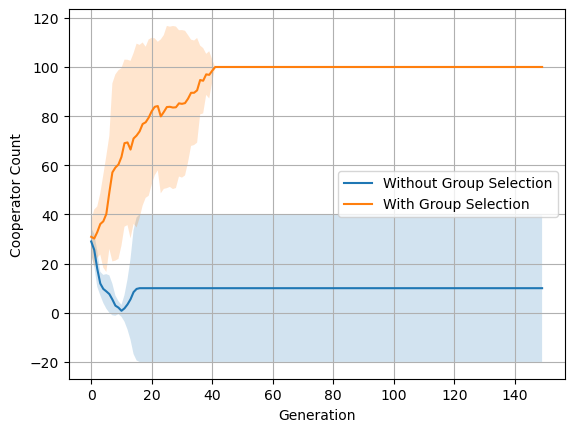

In [4]:
labels = {
    (False, False) : "With Group Selection",
    (False, True) : "Without Group Selection",
    # (True, False) : "\\text{GS Only}",
}

# plt.title('GS: equal & probabilistic')
for i in range(len(mechanisms)):
    plt.plot(mean_cooperation_per_gen[i], label=f'{labels[mechanisms[i]]}')
    plt.fill_between(np.arange(num_generations), mean_cooperation_per_gen[i] - std_cooperation_per_gen[i], 
                     mean_cooperation_per_gen[i] + std_cooperation_per_gen[i], alpha=0.2)
plt.legend(loc='center right')#, bbox_to_anchor=(1.05, 0.5))
plt.ylabel('Cooperator Count')
plt.xlabel('Generation')
plt.grid()
# plt.savefig("..\\figures\\temp\\mech.png", bbox_inches='tight', transparent=True)
plt.show()

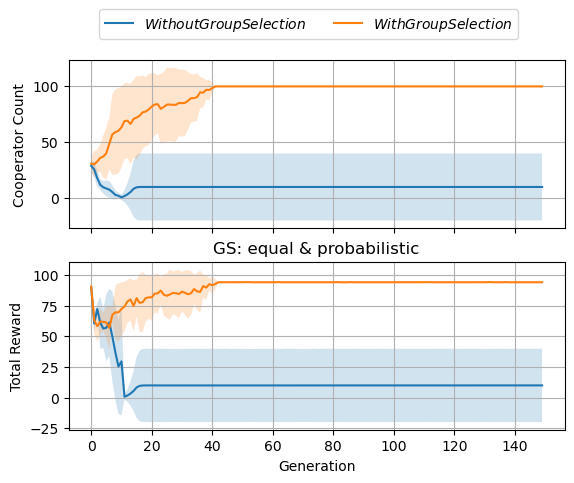

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.8))
plt.title('GS: equal & probabilistic', loc='center')

for i in range(len(mechanisms)):
    ax1.plot(mean_cooperation_per_gen[i], label=f'${labels[mechanisms[i]]}$')
    ax1.fill_between(np.arange(num_generations), mean_cooperation_per_gen[i] - std_cooperation_per_gen[i], 
                     mean_cooperation_per_gen[i] + std_cooperation_per_gen[i], alpha=0.2)
ax1.set(ylabel='Cooperator Count')
ax1.grid()

for i in range(len(mechanisms)):
    ax2.plot(mean_total_reward_per_gen[i], label='')
    ax2.fill_between(np.arange(num_generations), mean_total_reward_per_gen[i] - std_total_reward_per_gen[i], 
                     mean_total_reward_per_gen[i] + std_total_reward_per_gen[i], alpha=0.2)
ax2.set(xlabel='Generation', ylabel='Total Reward')
ax2.grid()

fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1), ncol=5)

# plt.savefig("..\\figures\\temp\\var_cost_benefit_condensed_sd.png", bbox_inches='tight', transparent=True)
plt.show()


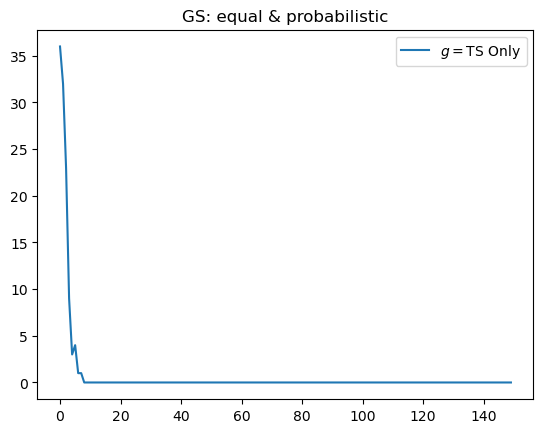

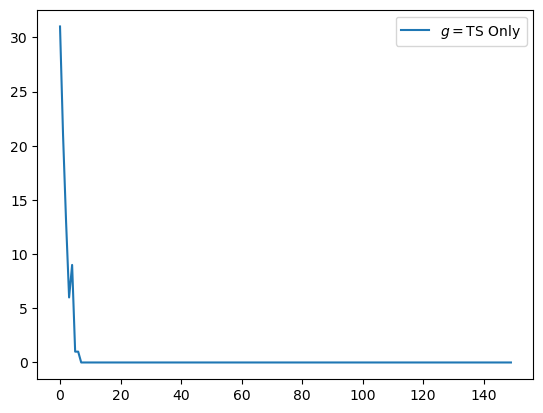

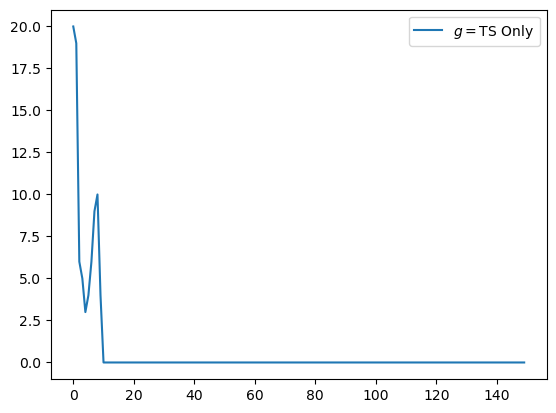

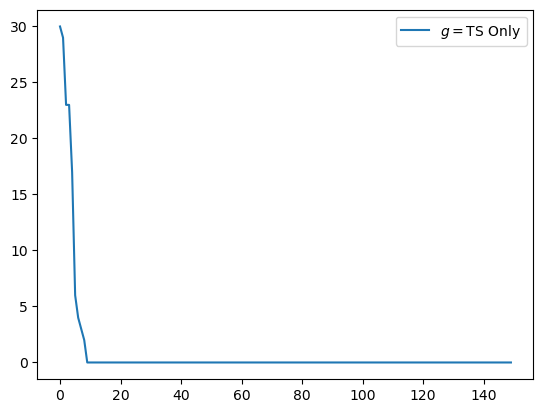

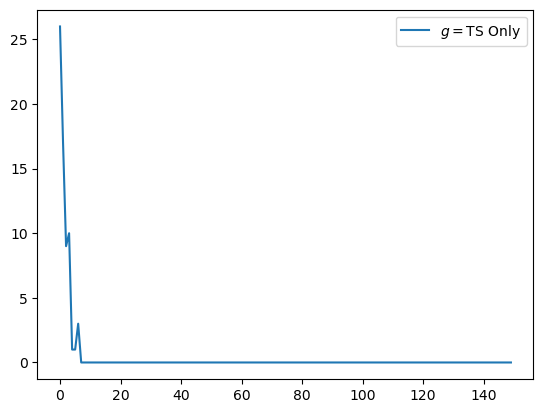

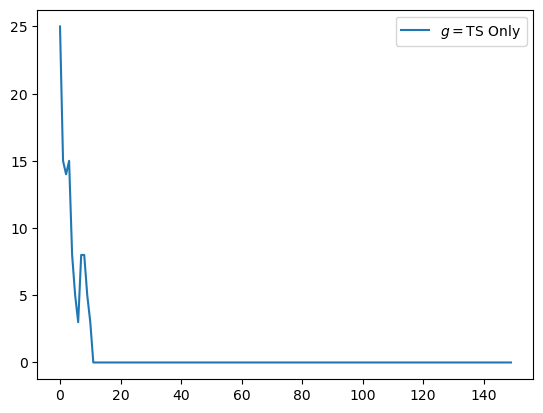

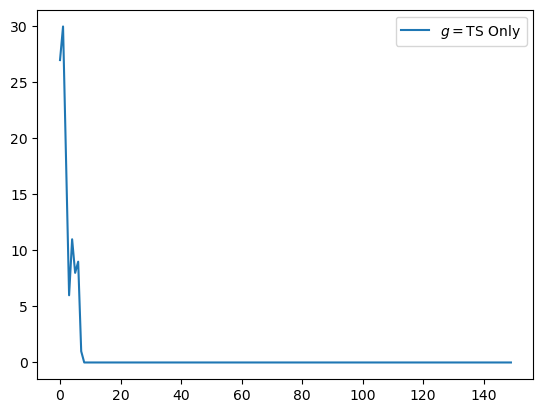

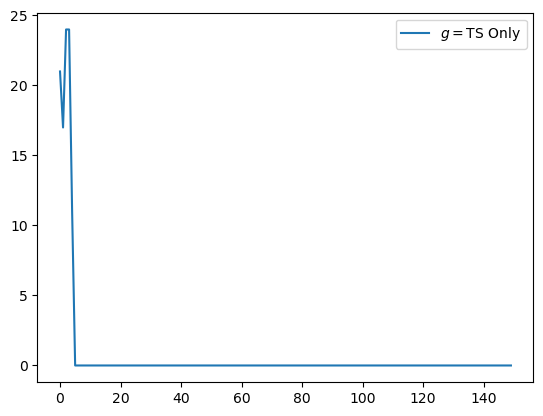

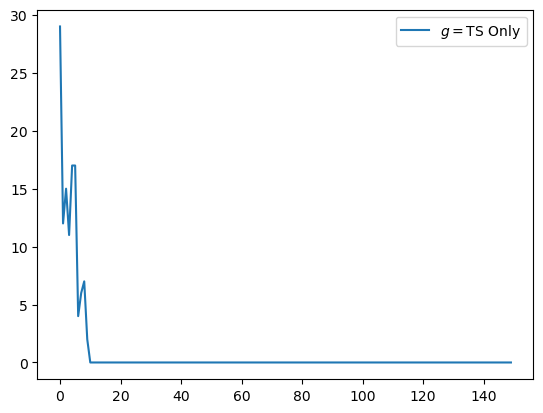

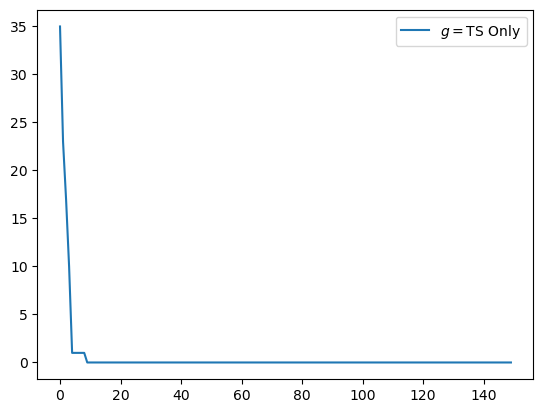

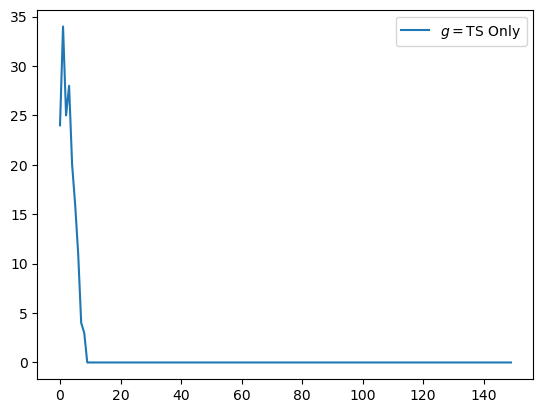

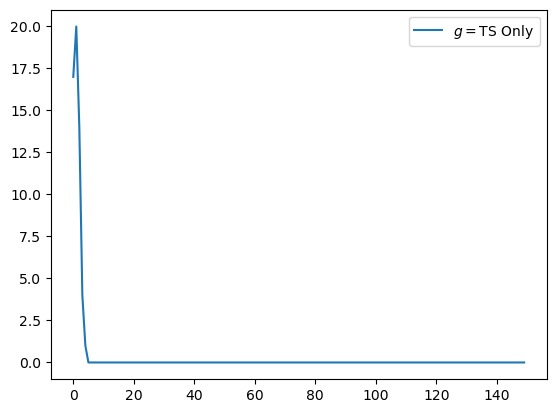

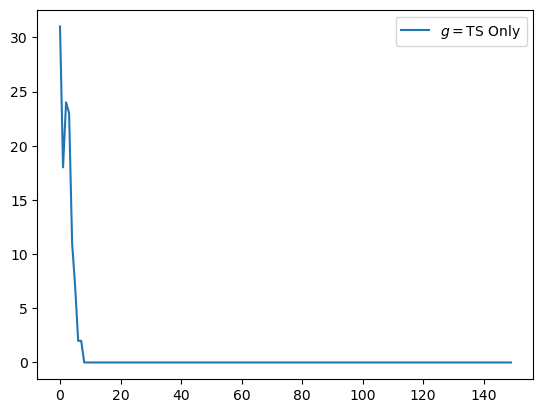

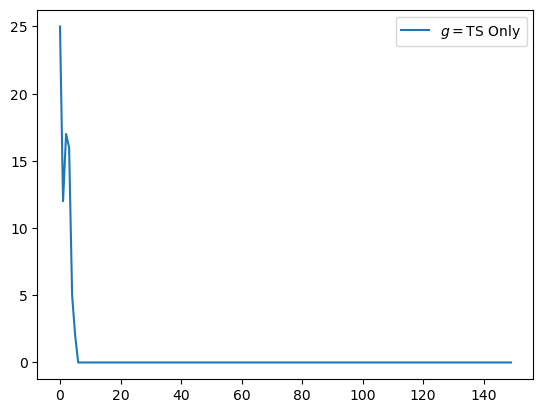

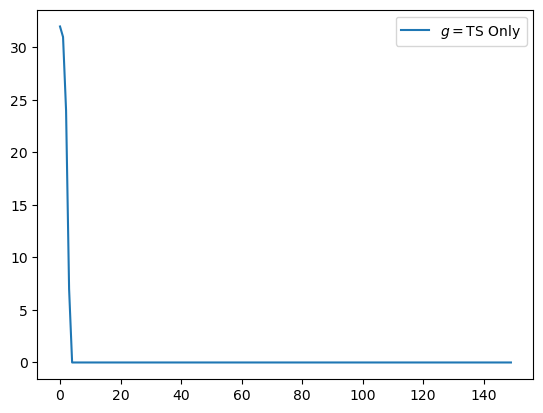

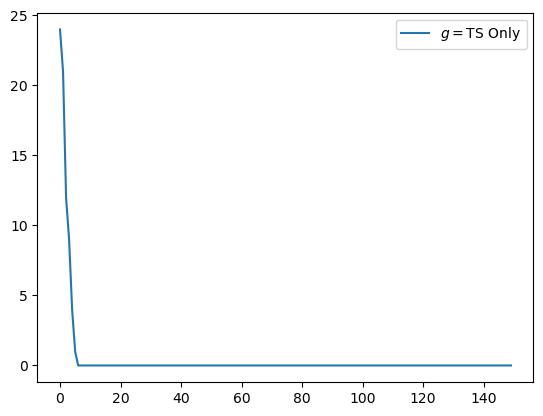

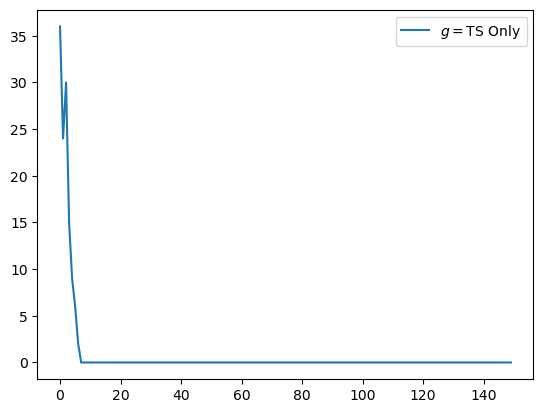

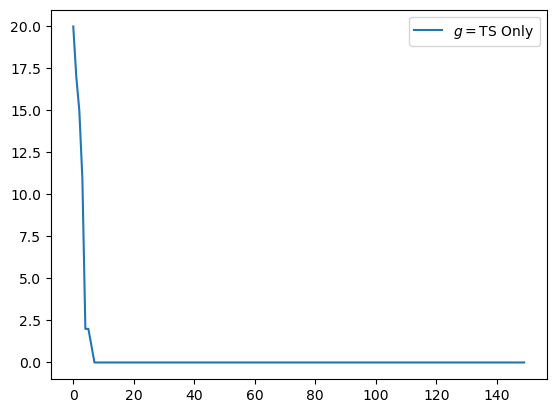

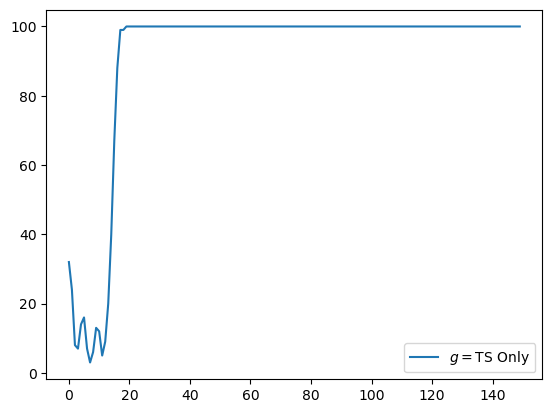

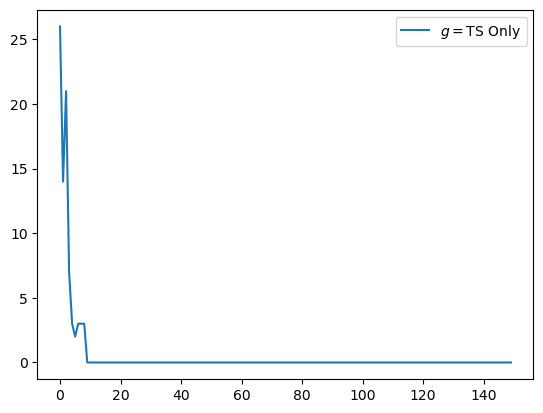

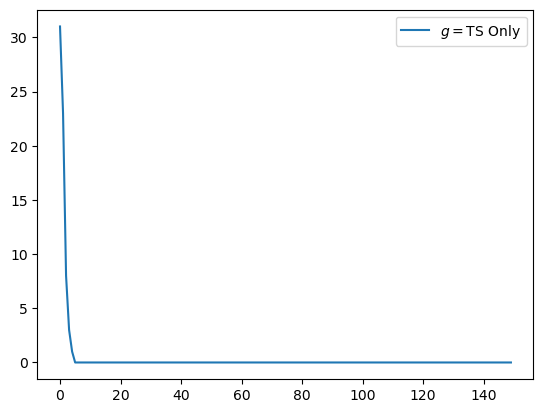

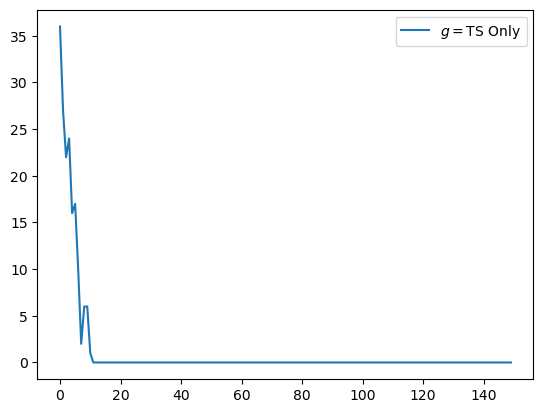

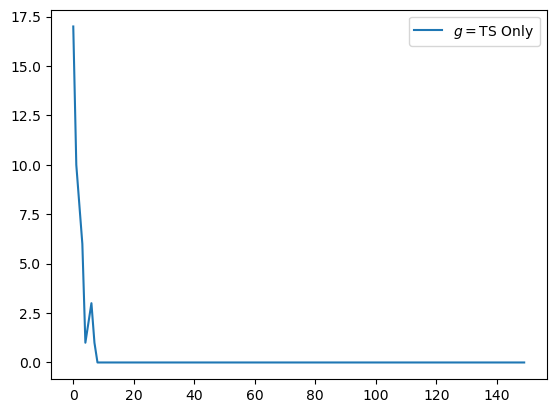

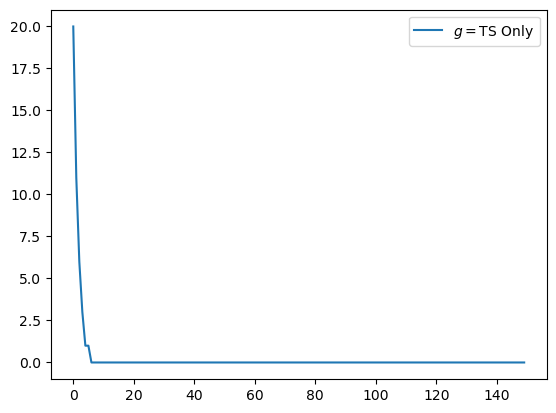

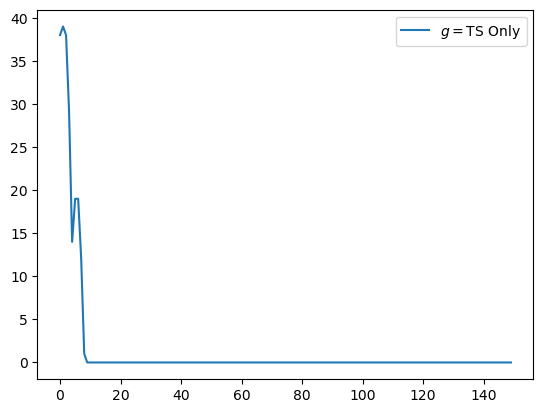

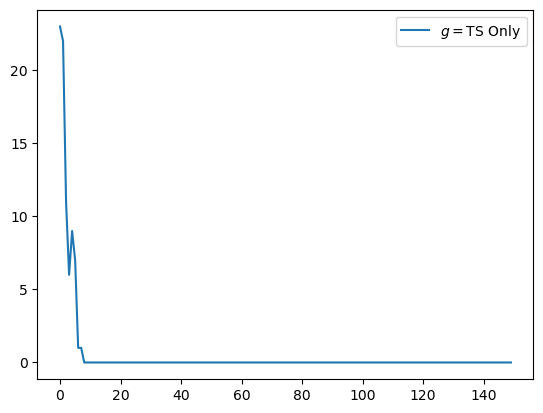

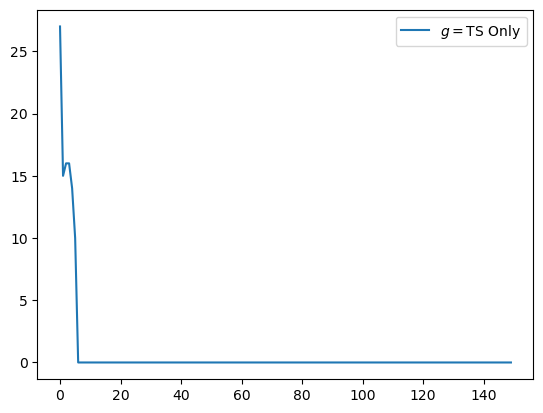

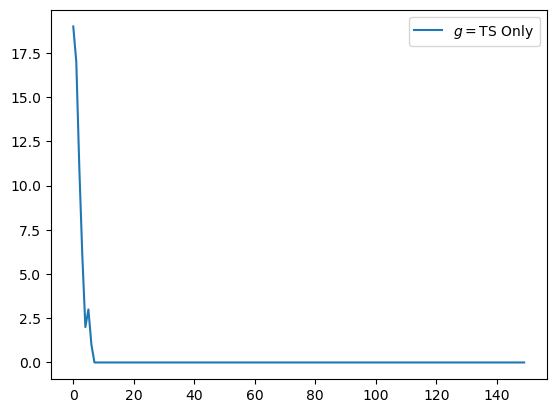

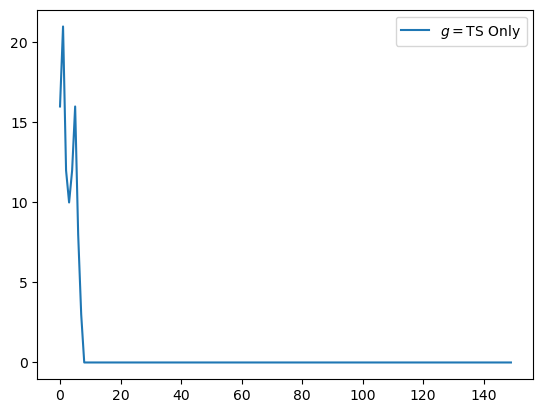

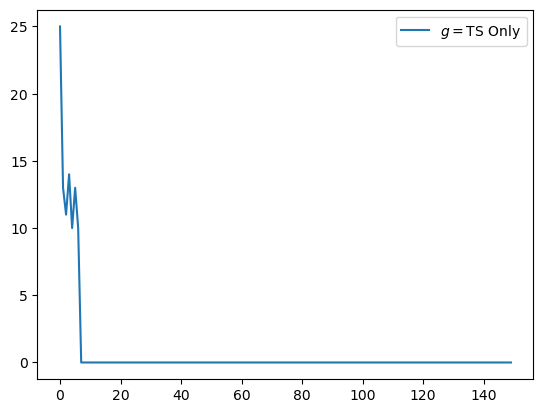

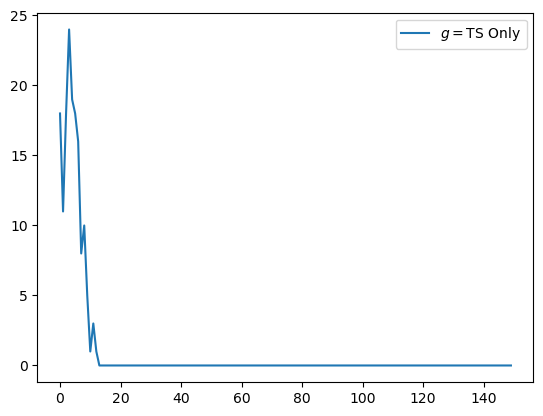

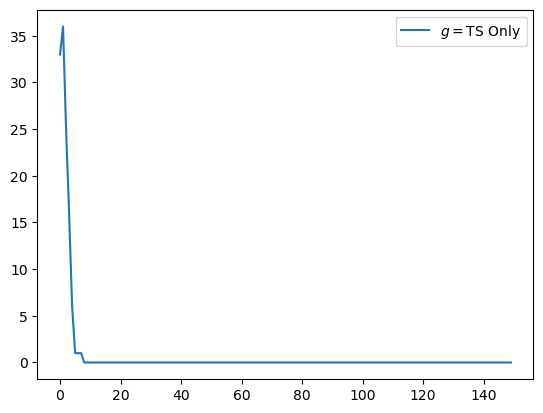

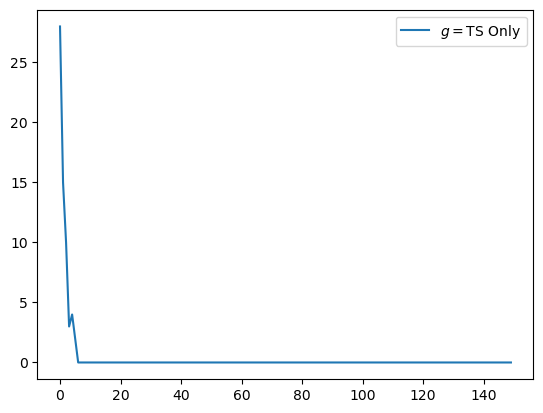

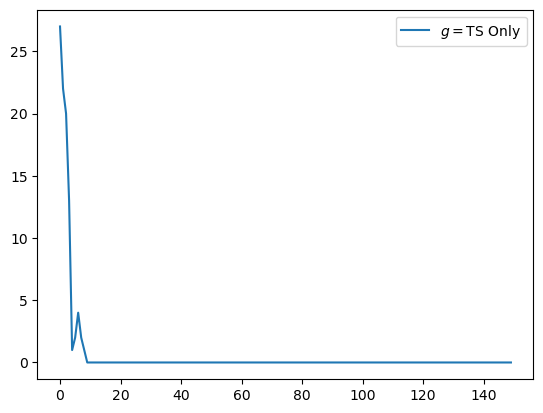

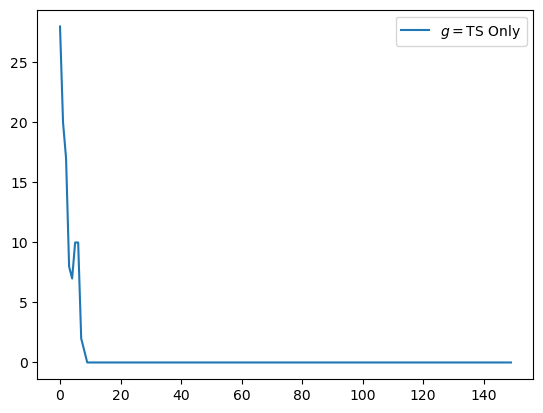

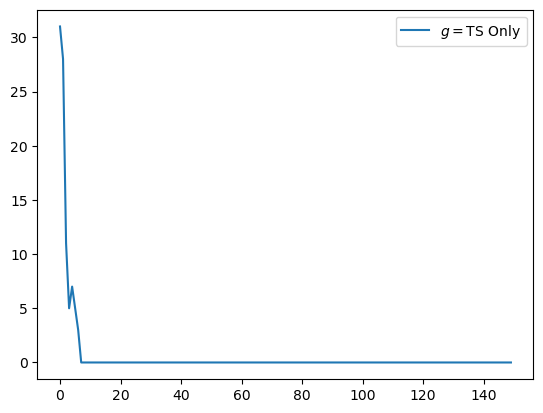

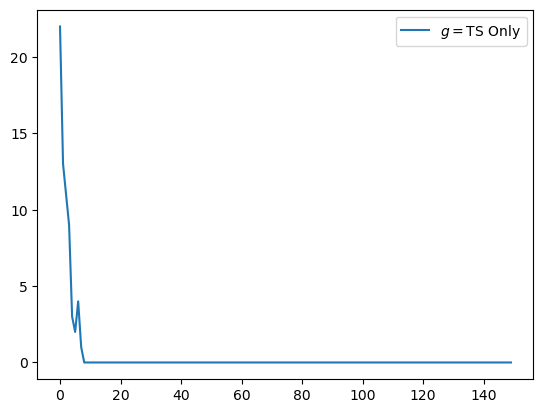

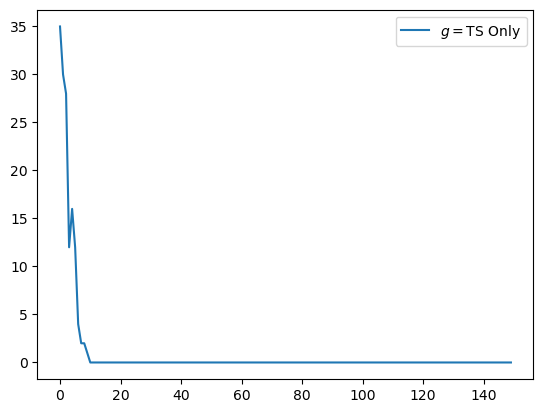

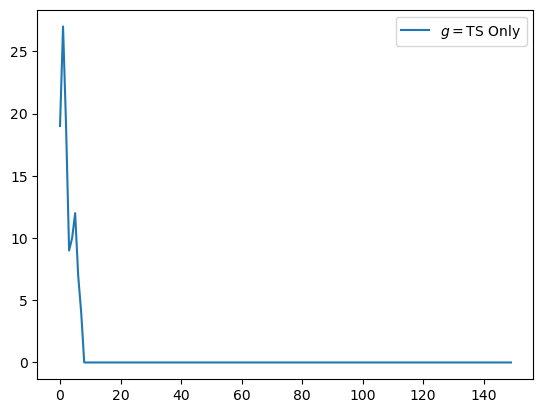

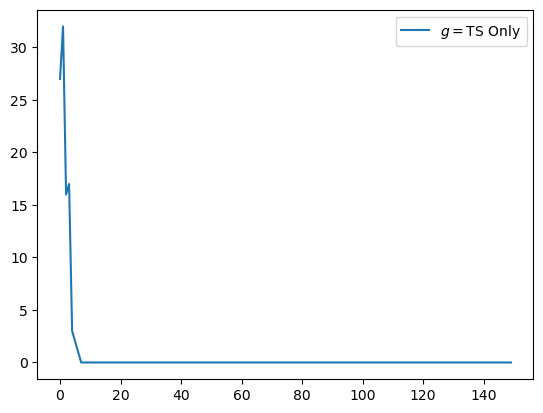

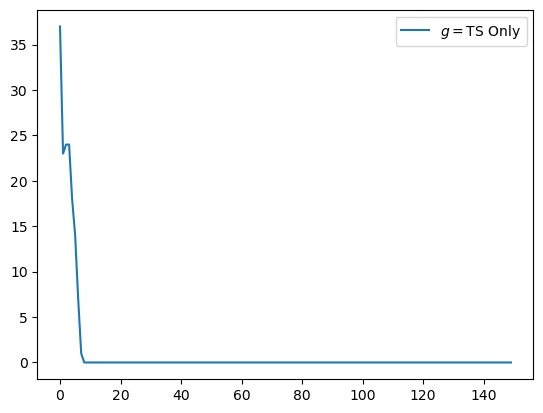

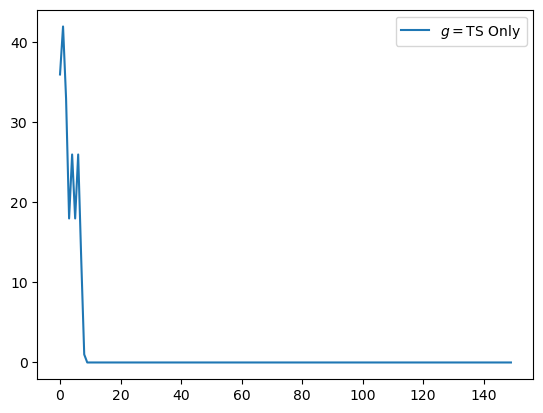

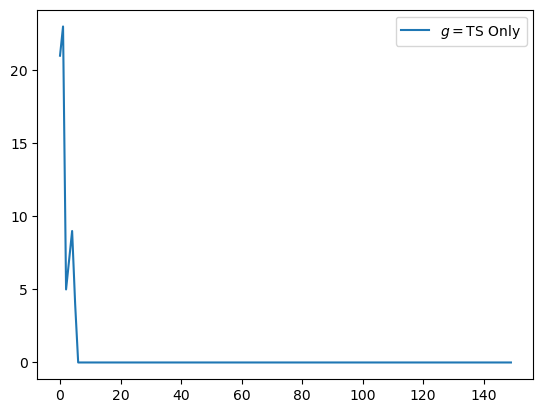

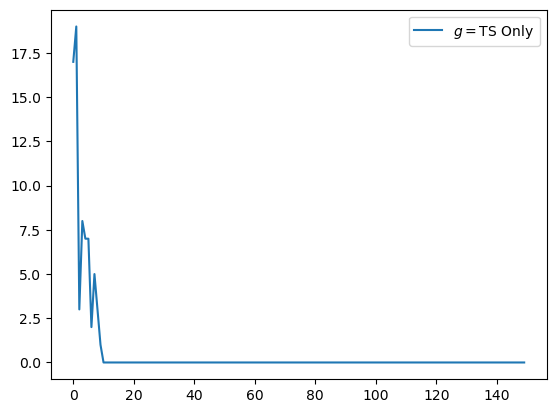

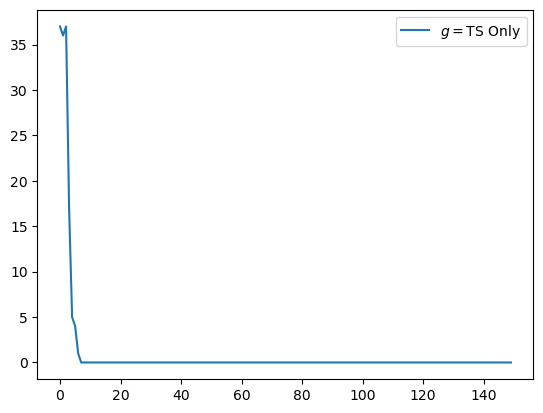

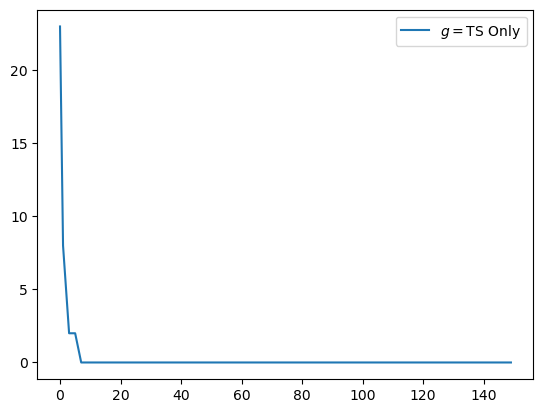

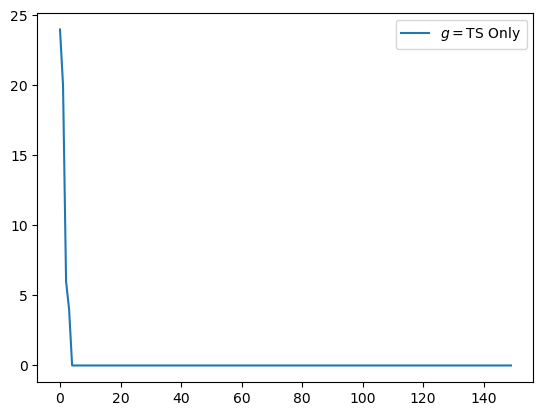

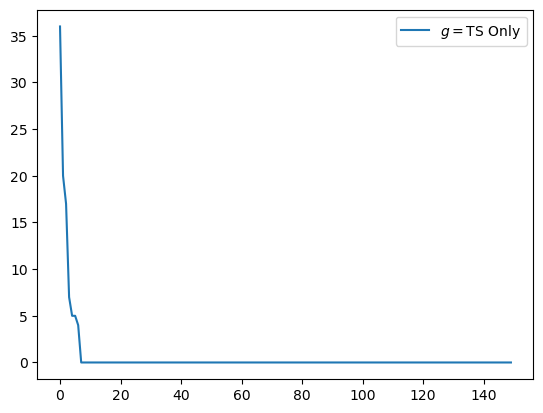

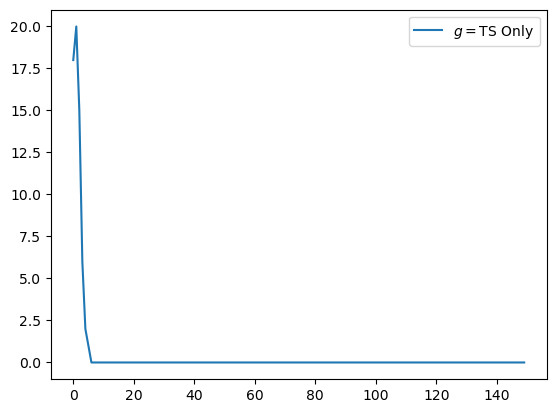

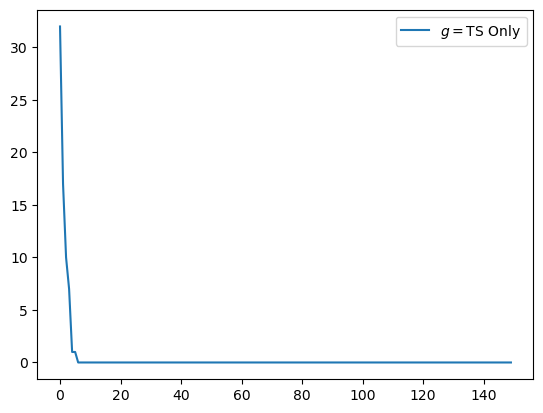

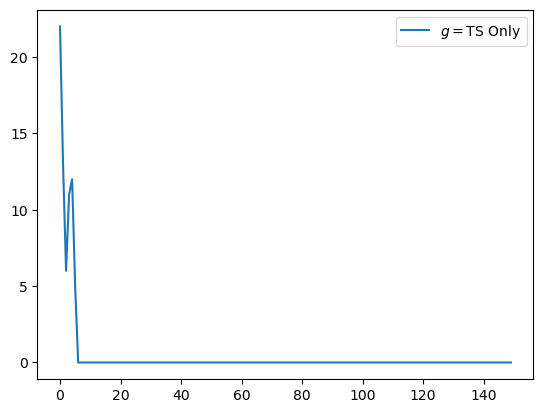

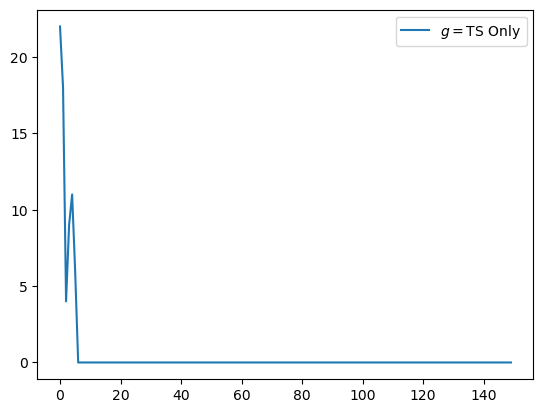

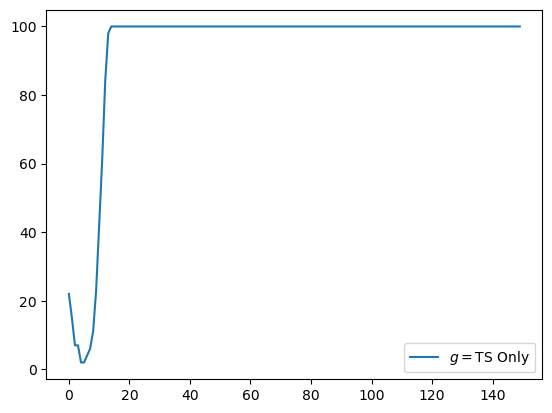

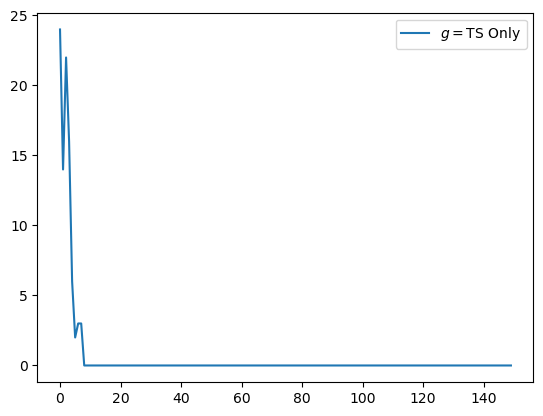

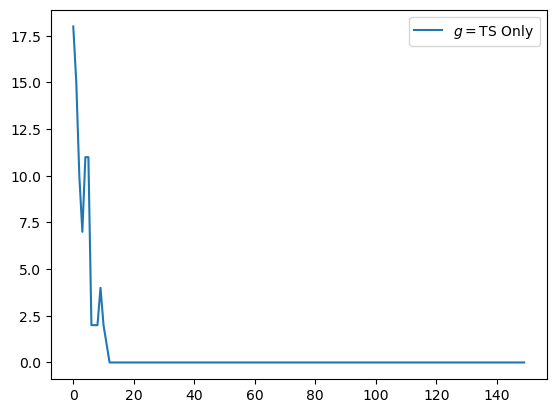

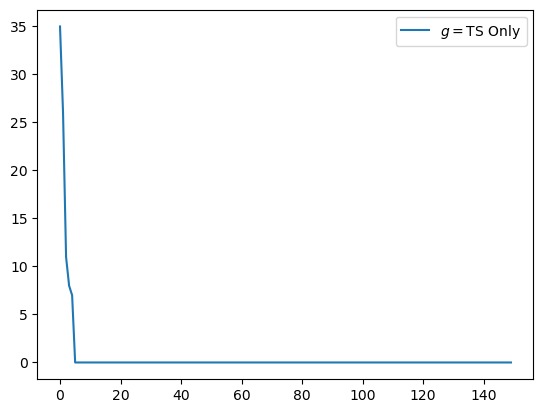

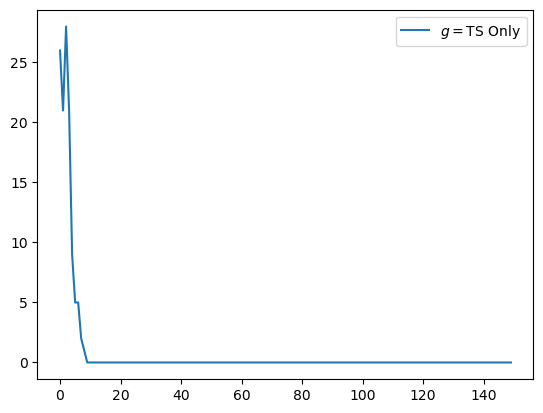

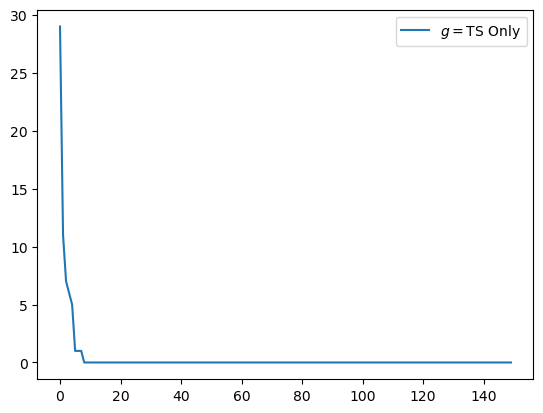

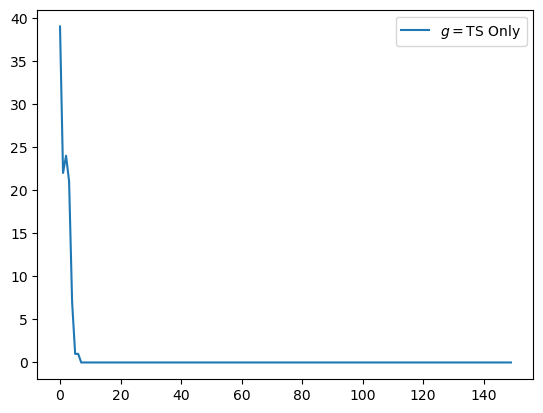

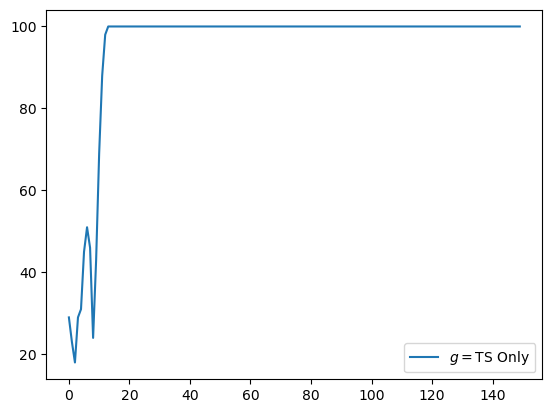

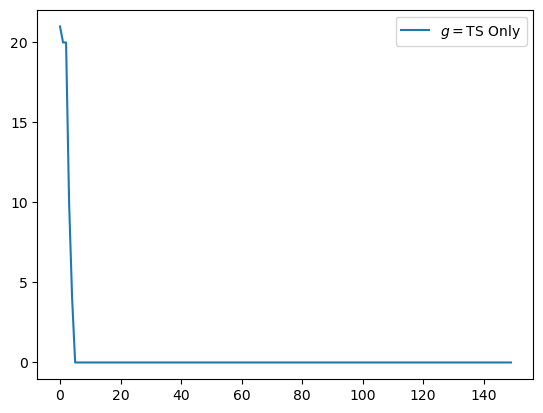

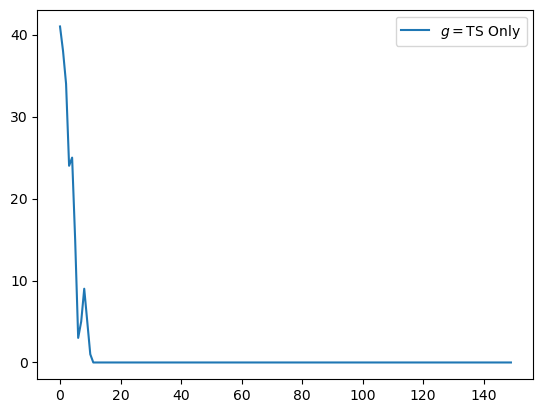

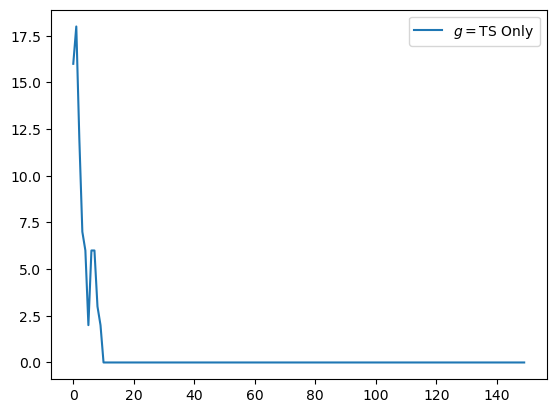

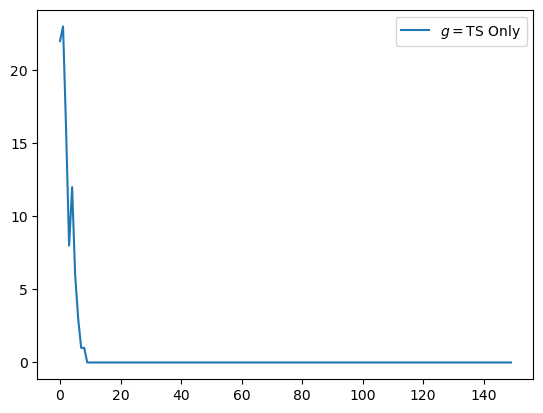

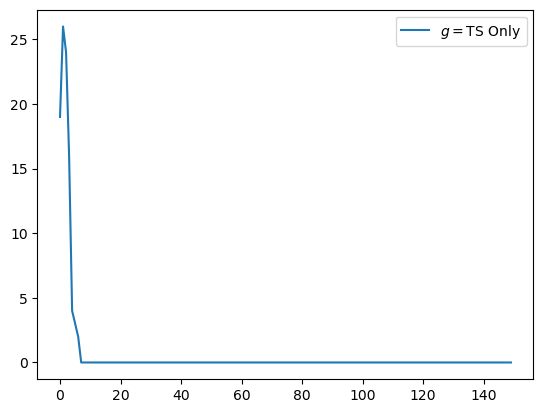

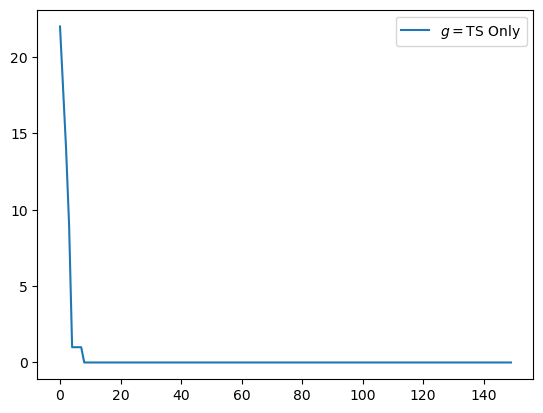

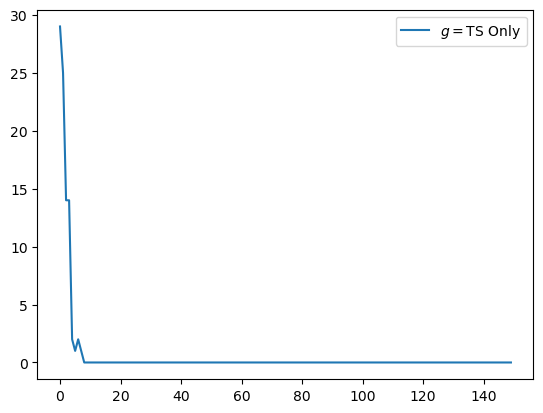

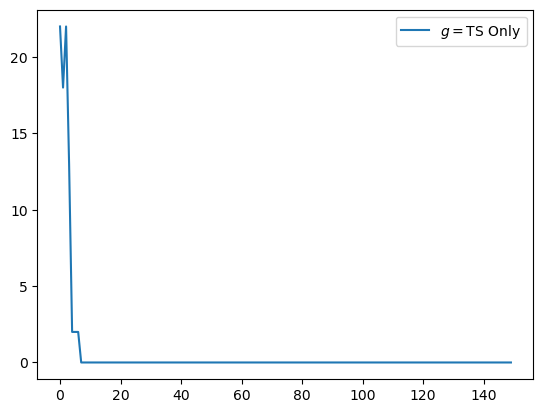

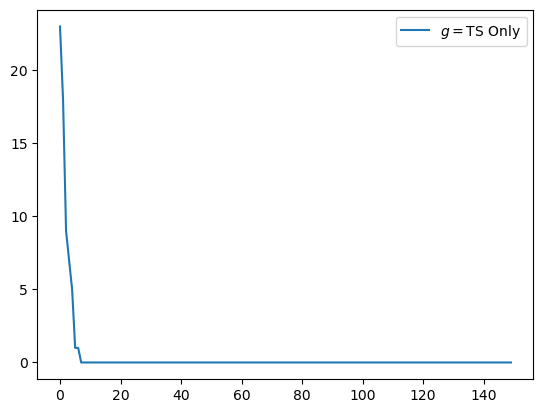

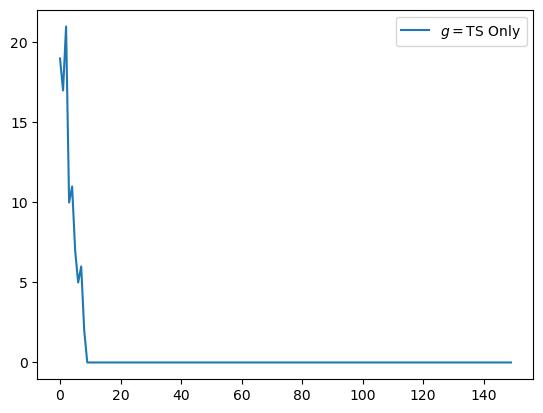

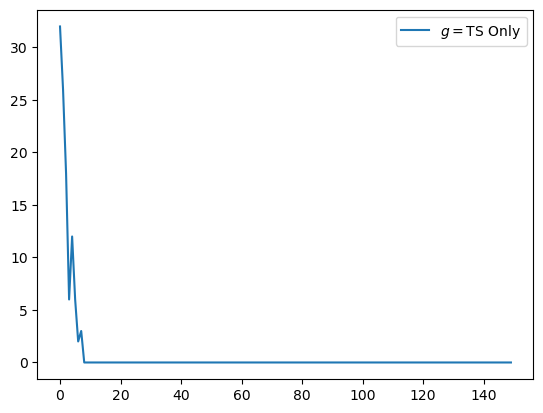

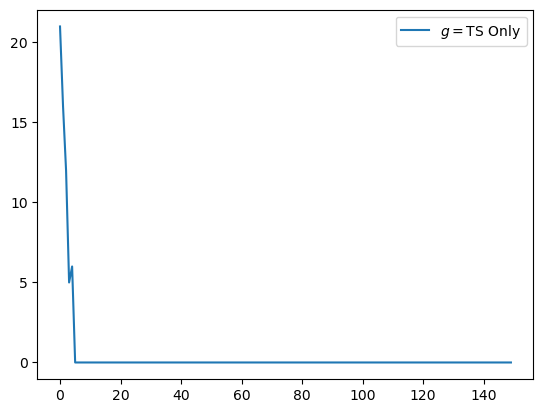

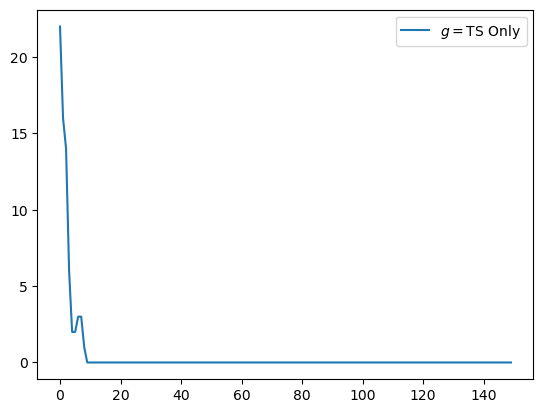

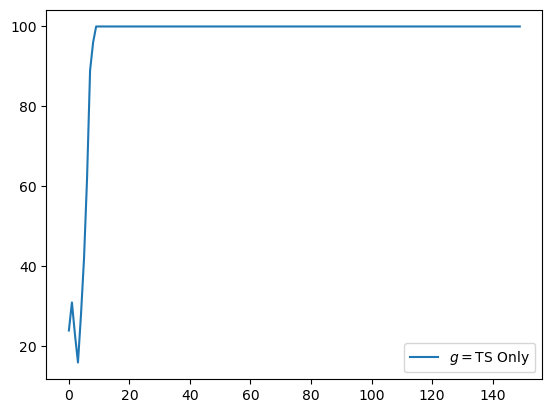

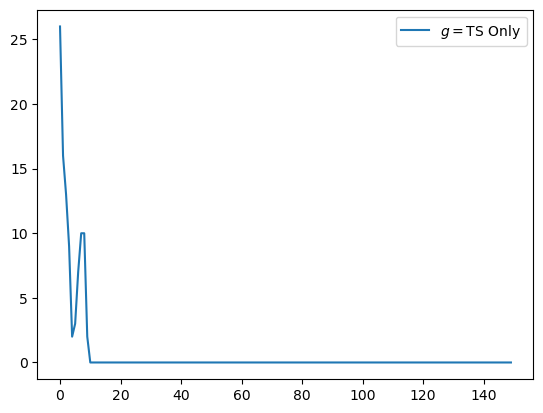

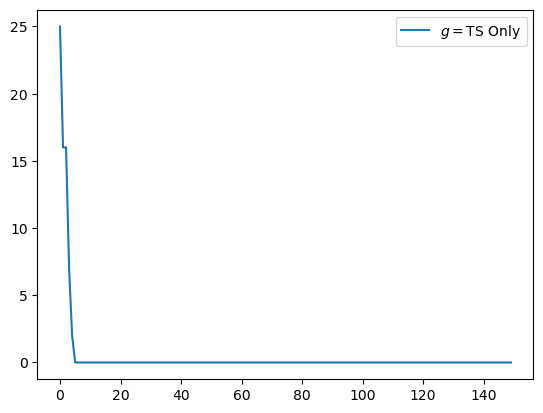

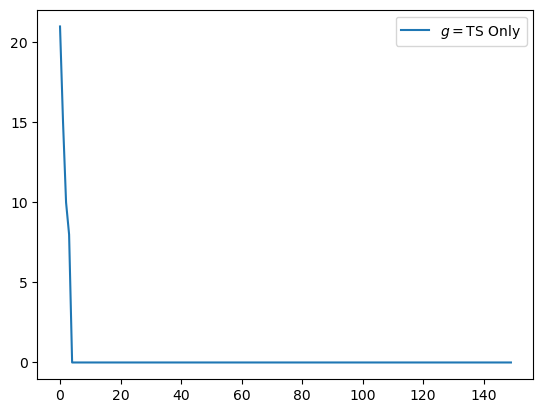

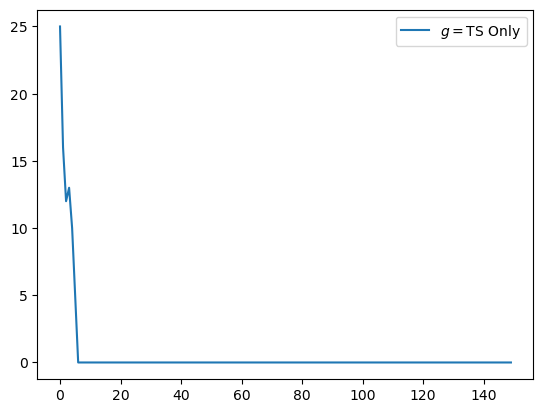

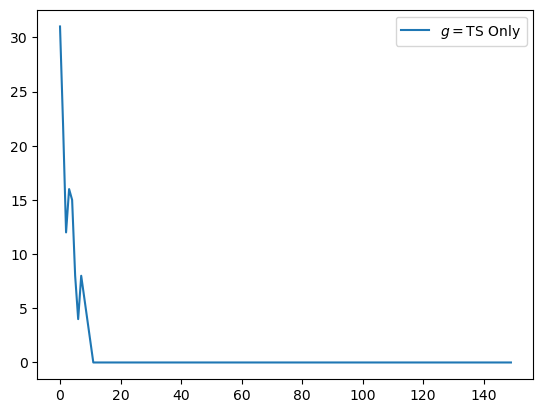

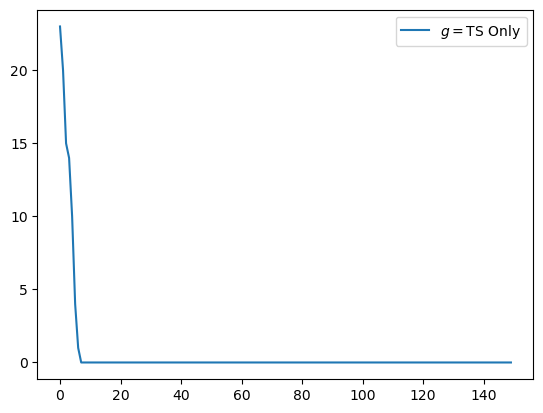

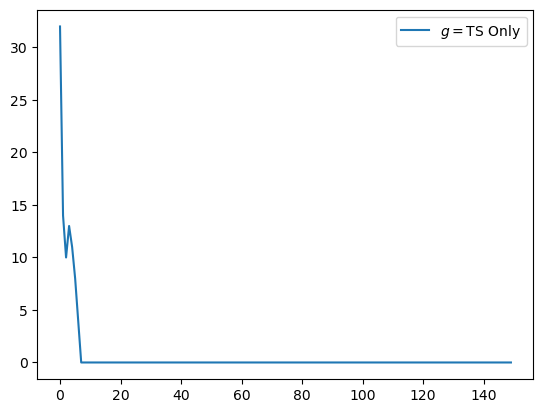

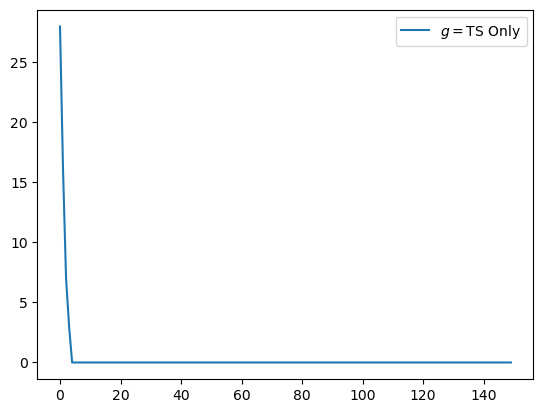

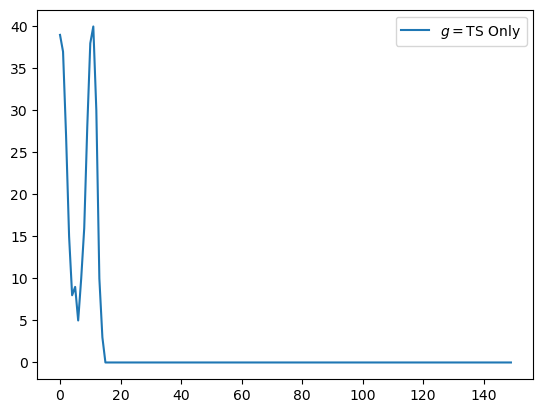

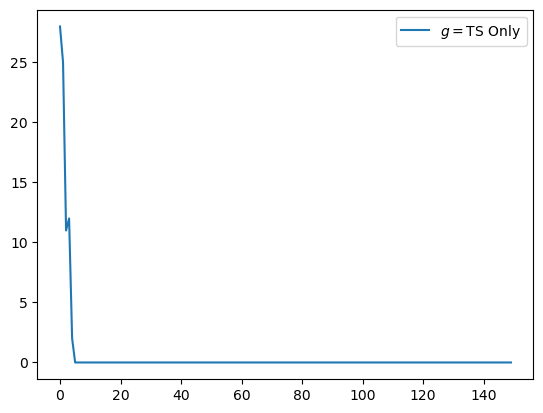

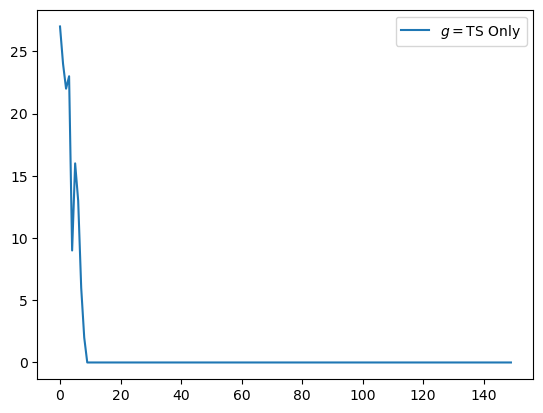

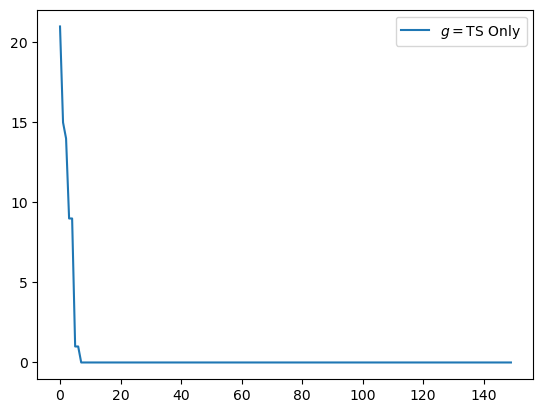

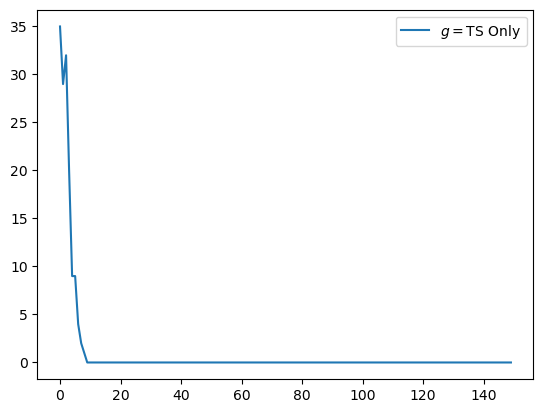

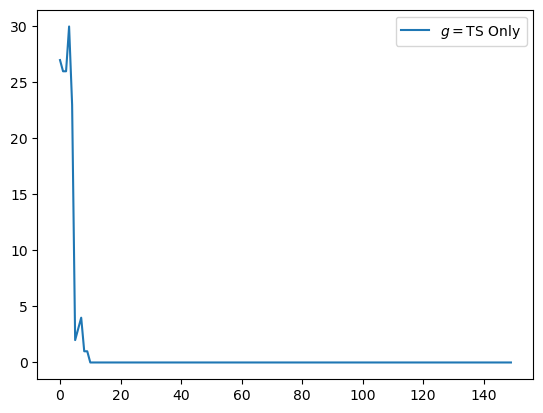

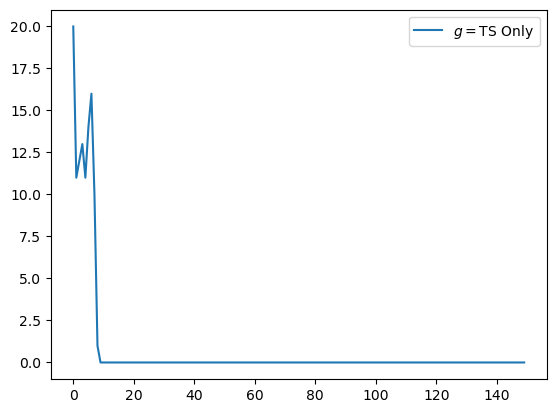

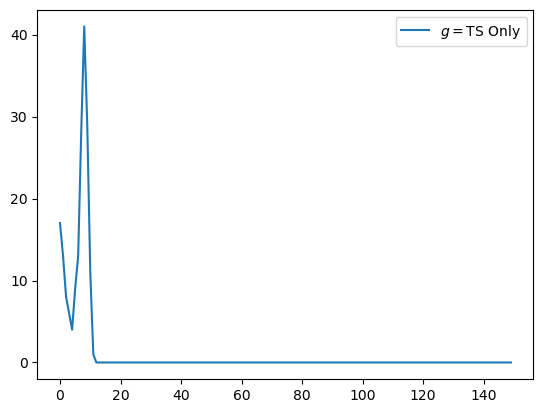

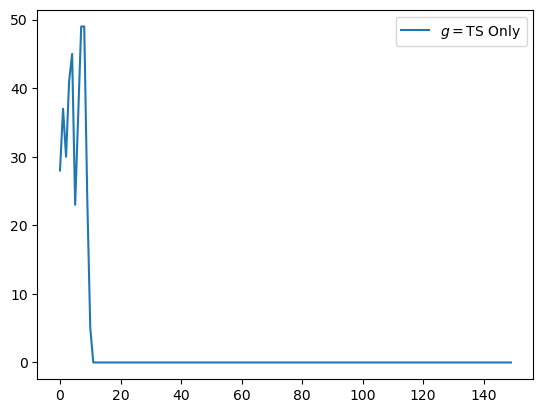

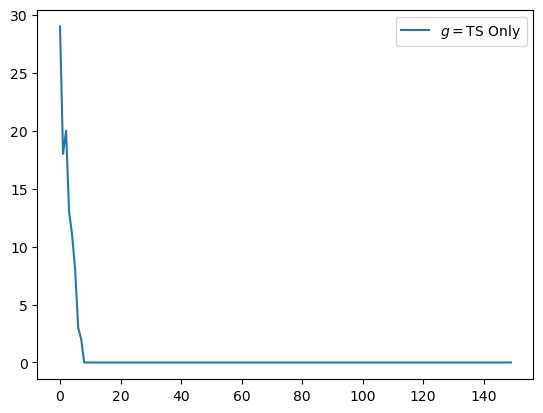

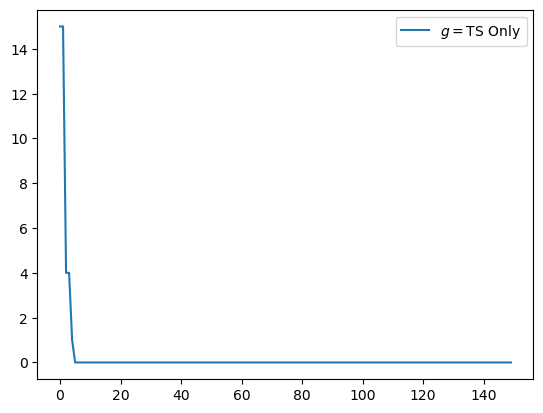

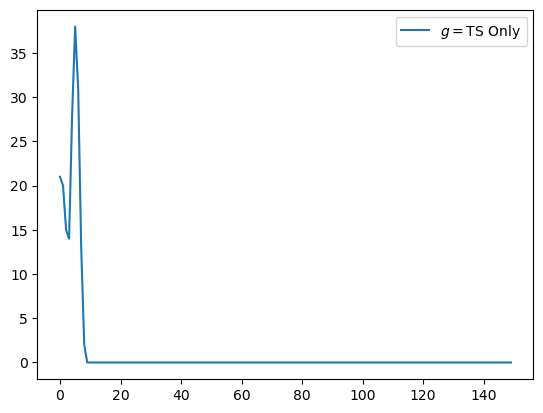

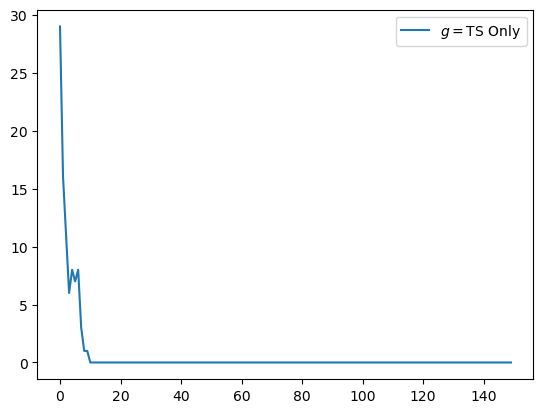

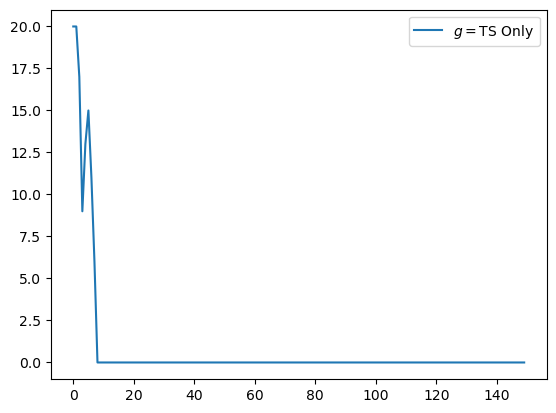

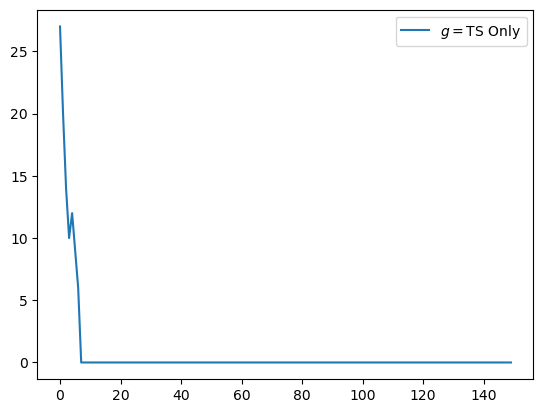

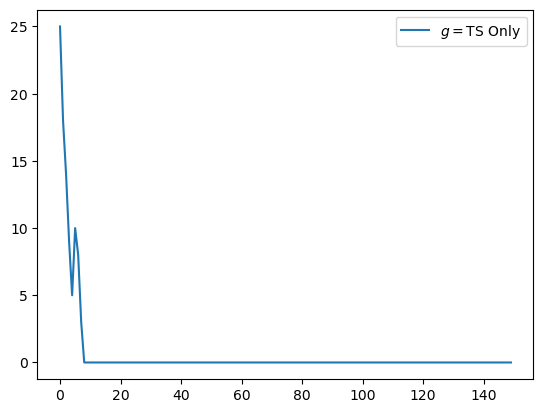

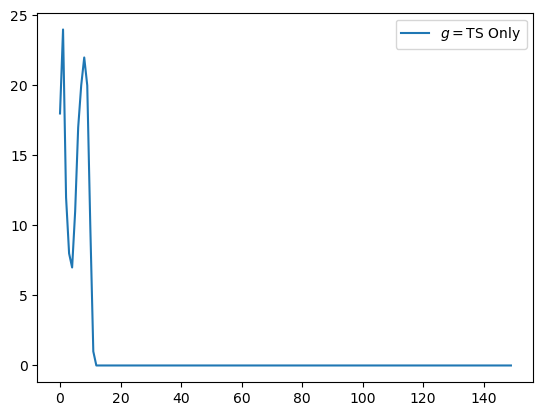

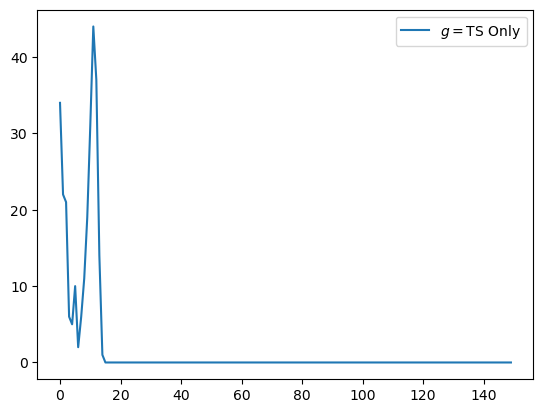

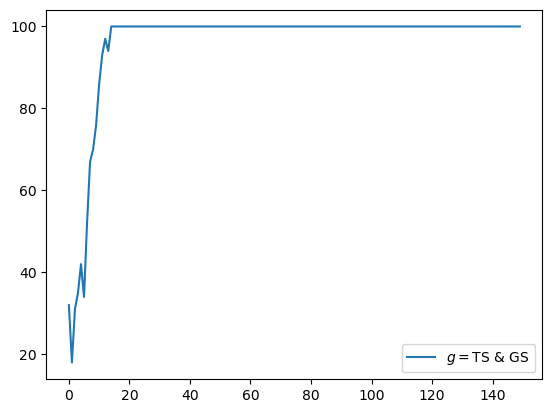

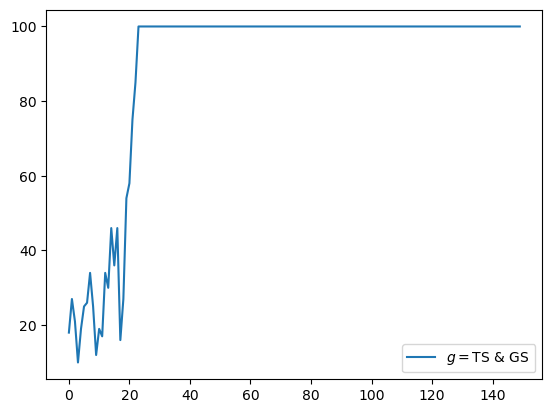

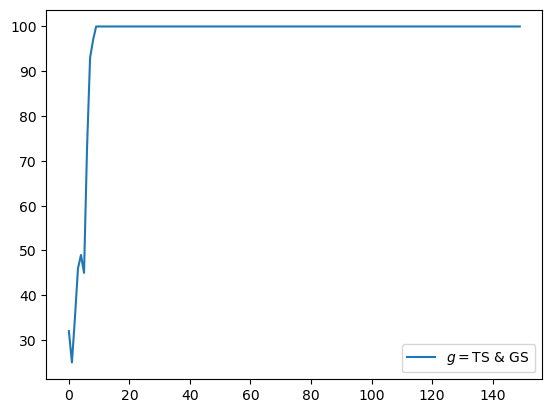

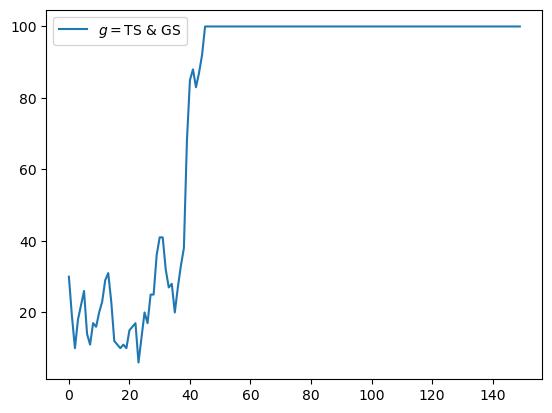

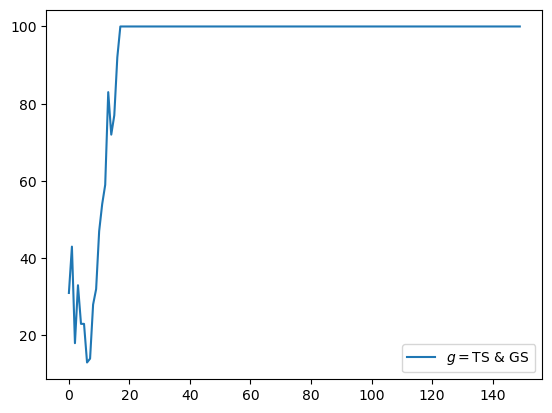

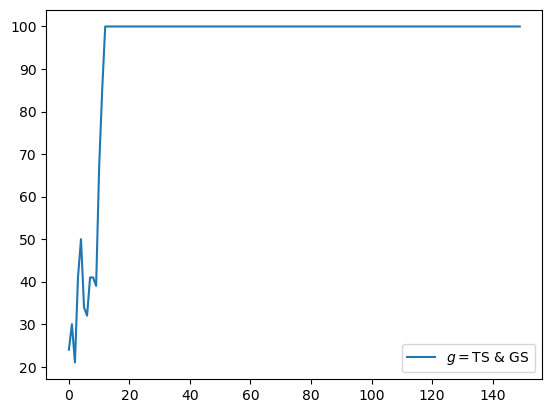

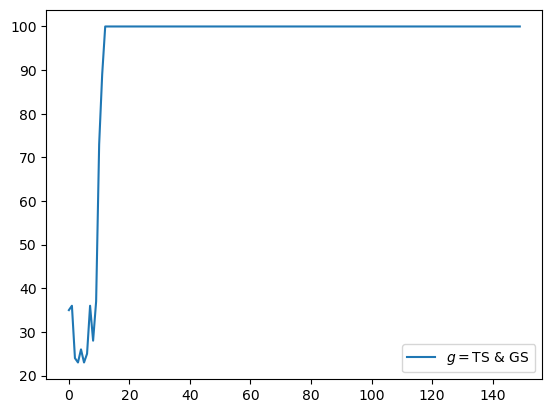

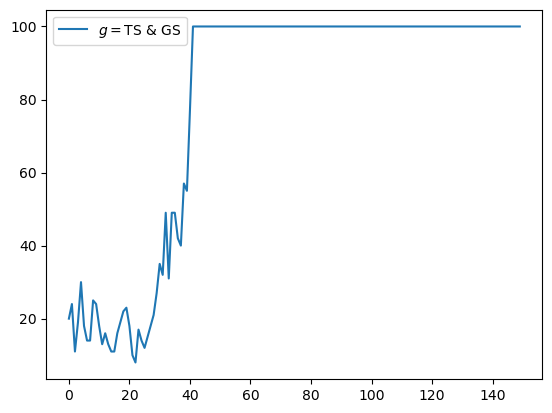

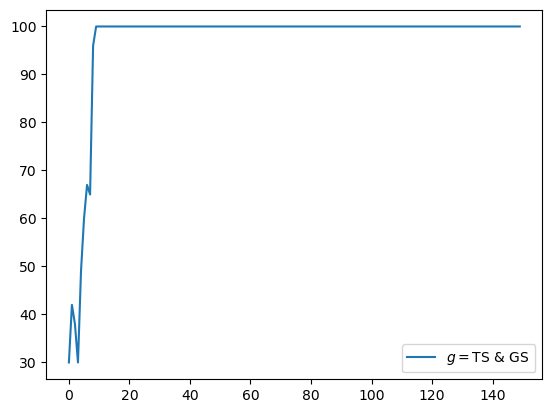

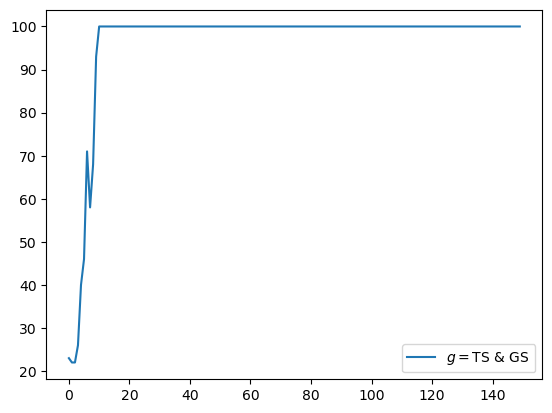

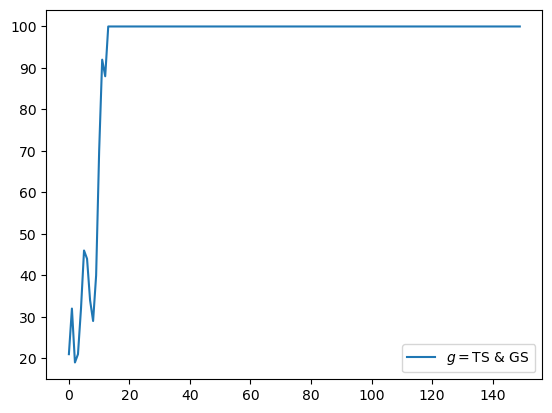

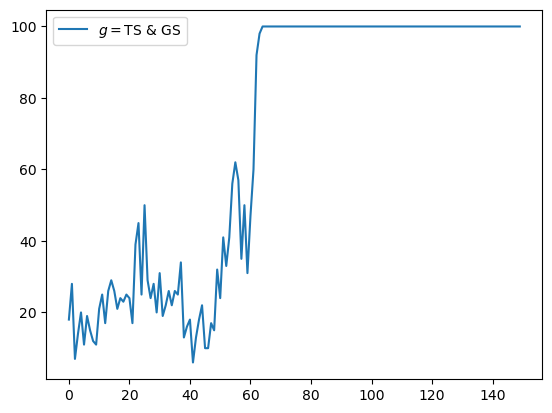

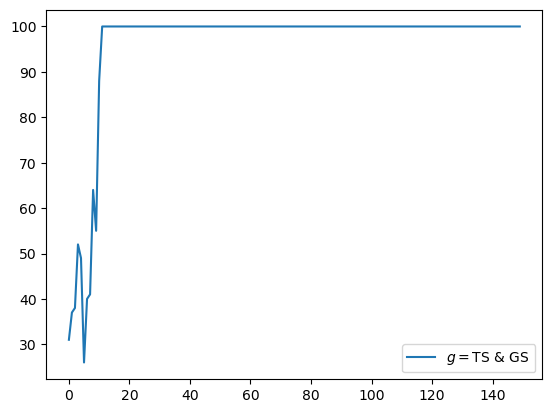

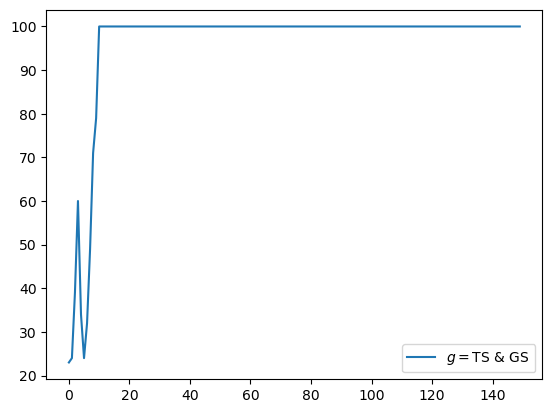

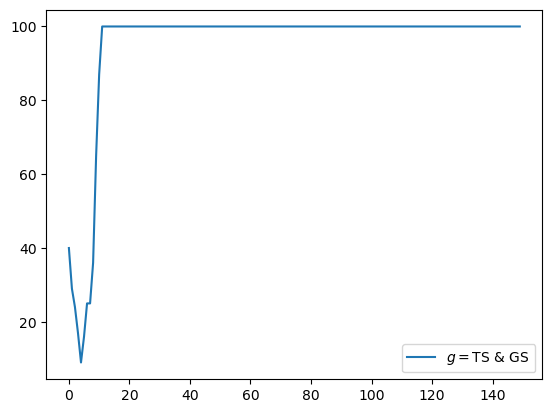

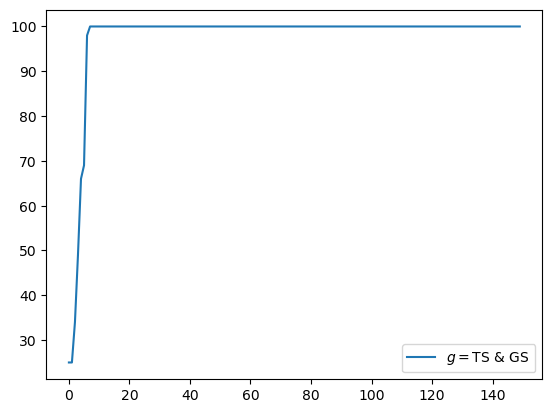

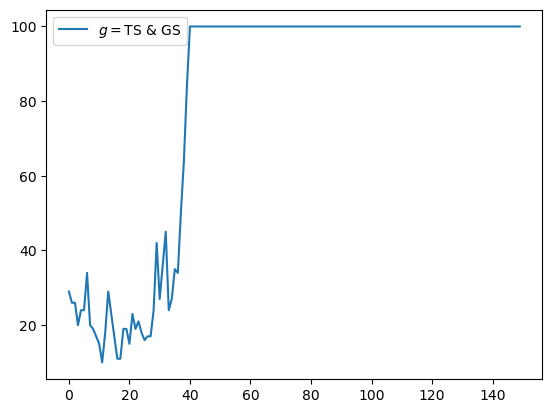

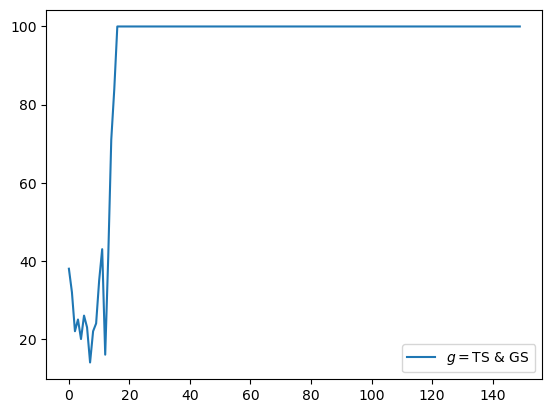

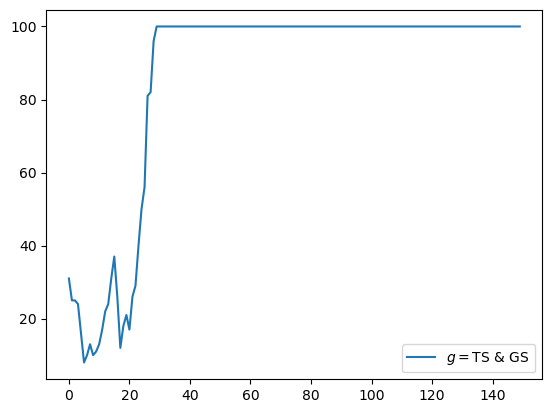

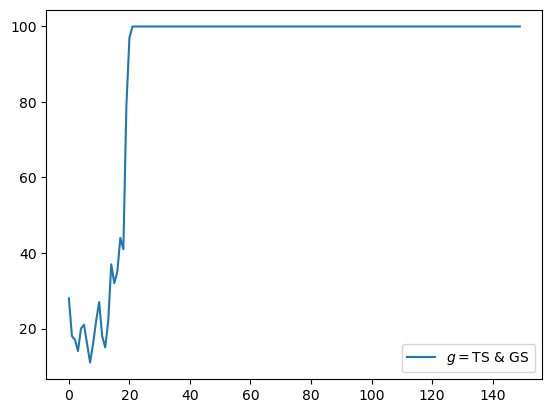

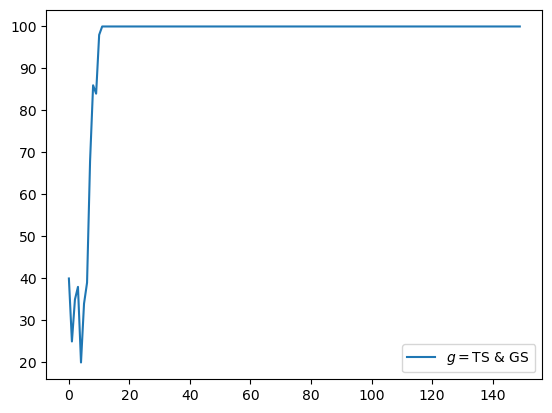

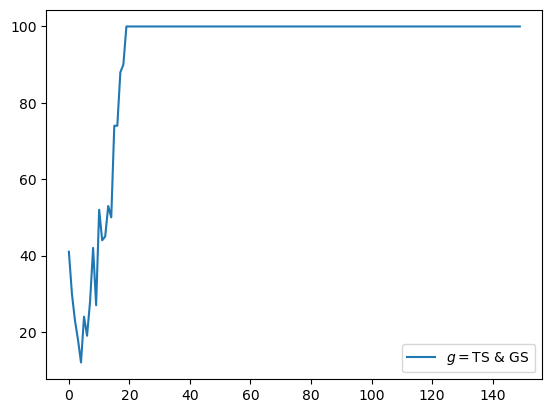

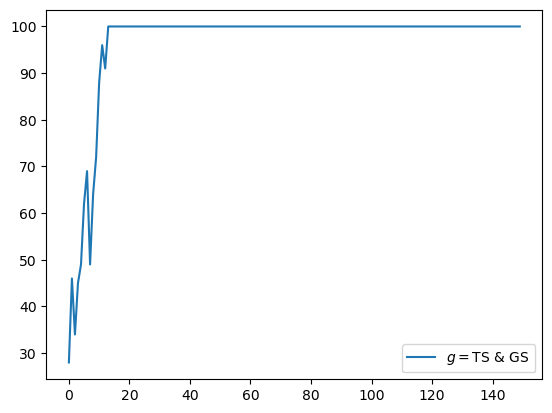

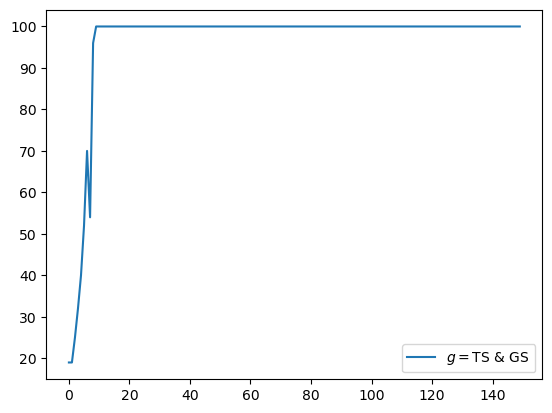

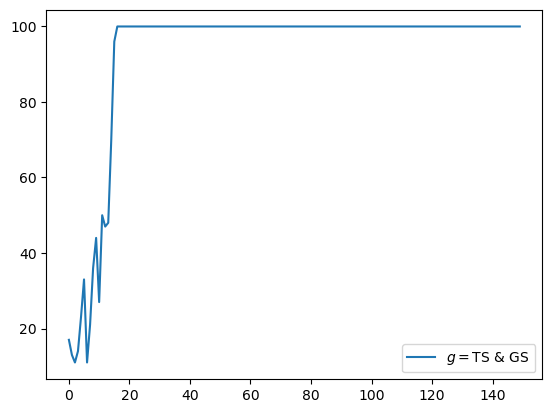

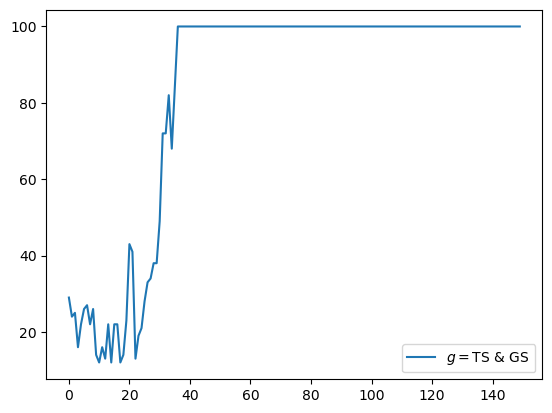

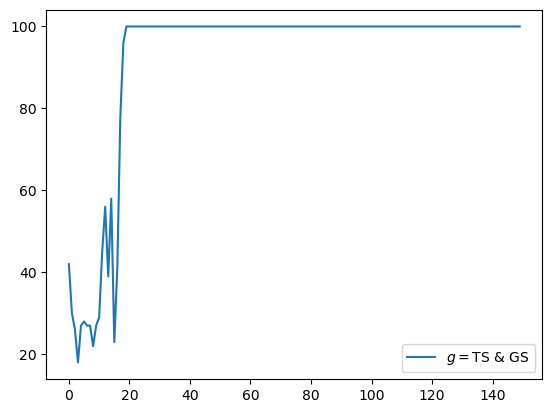

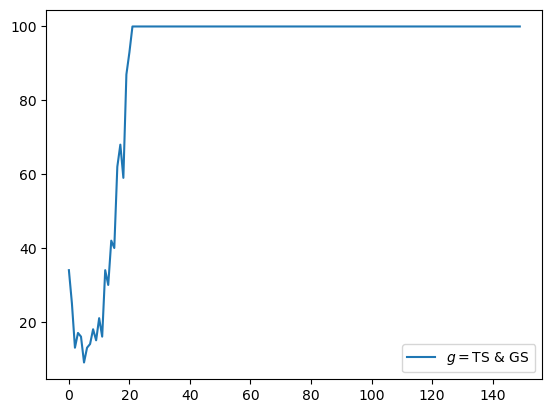

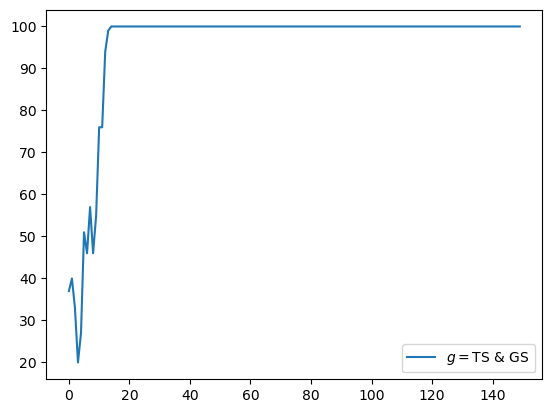

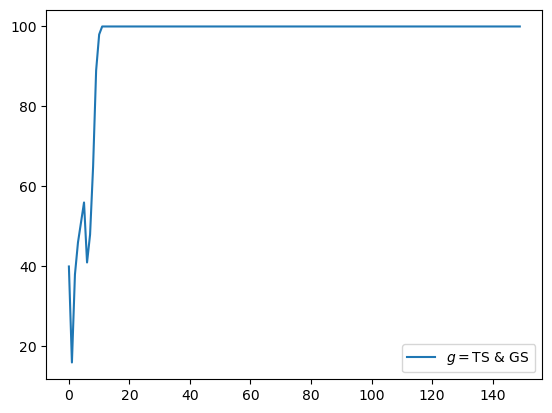

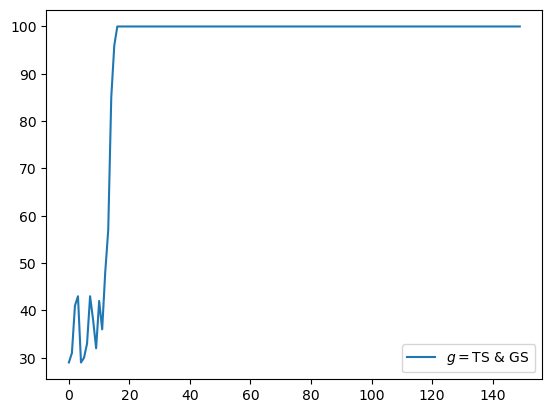

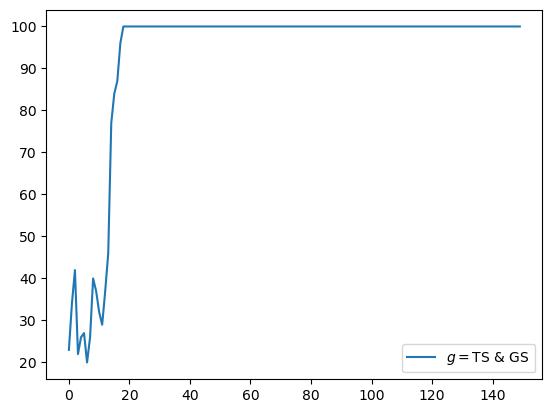

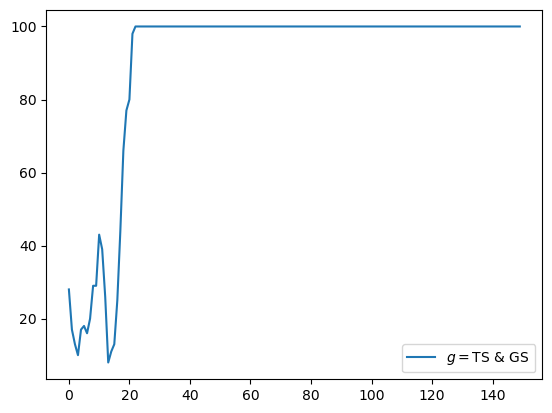

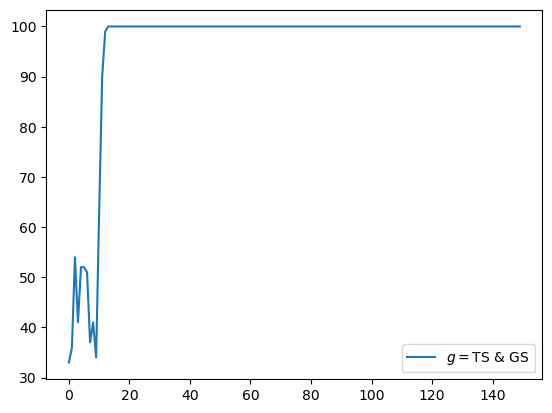

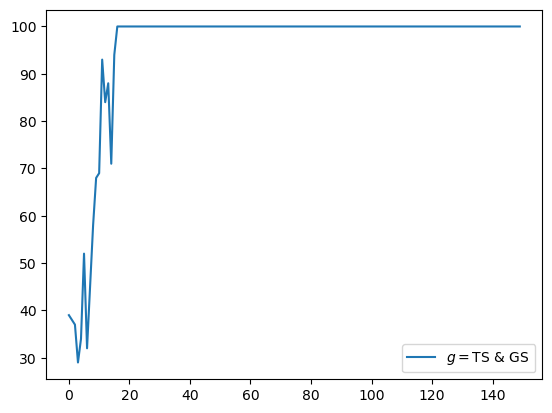

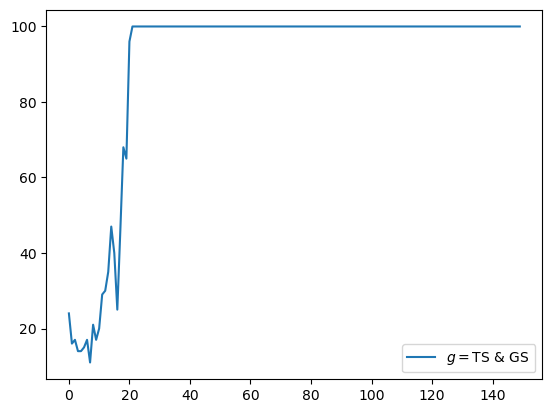

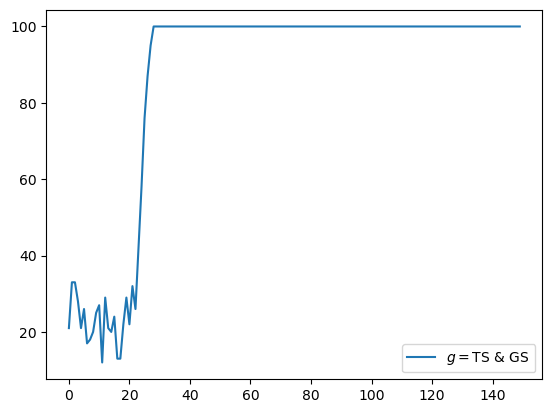

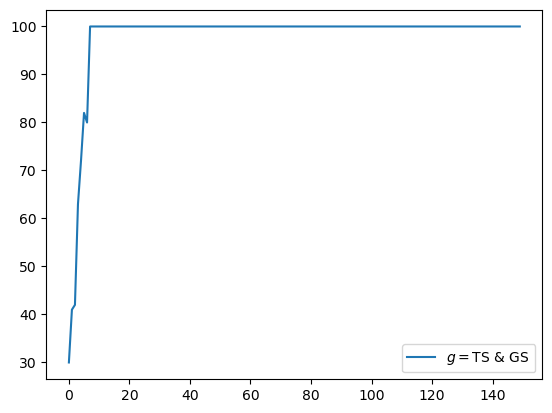

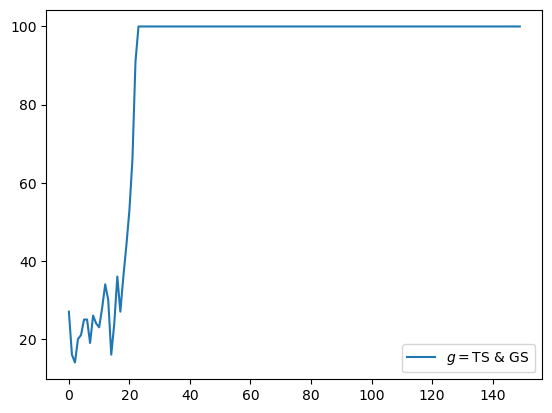

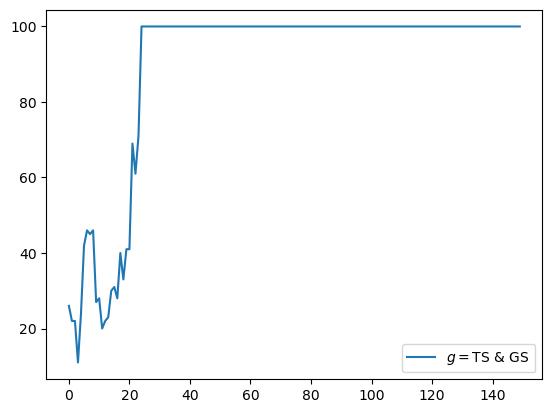

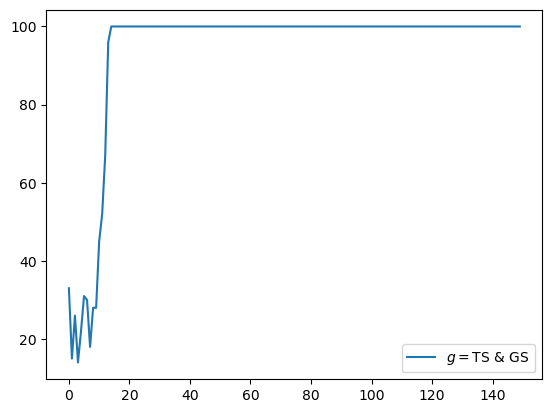

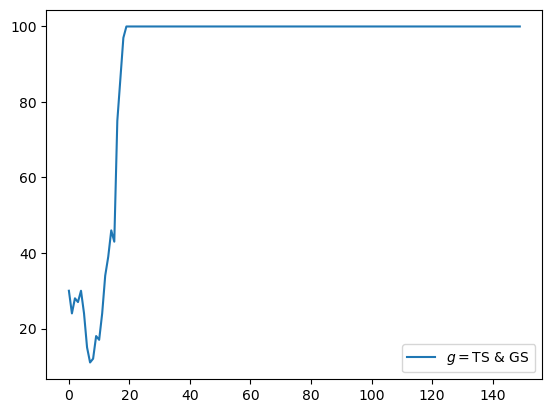

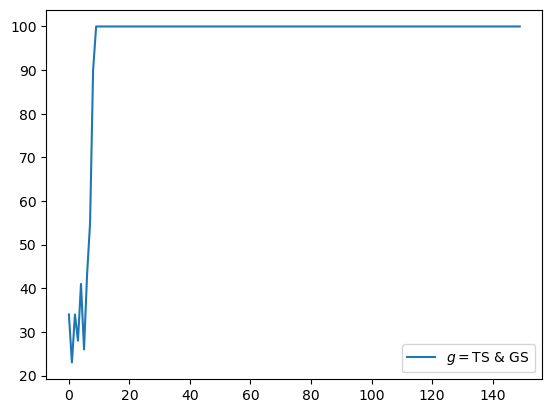

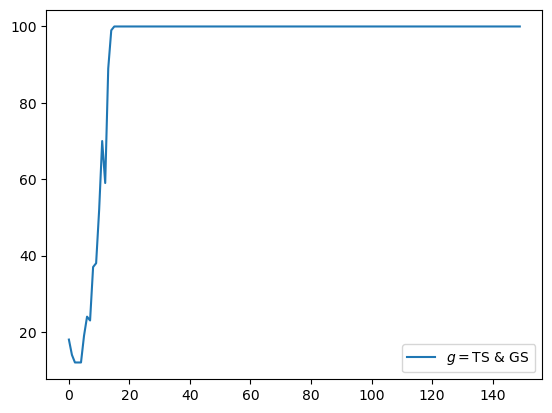

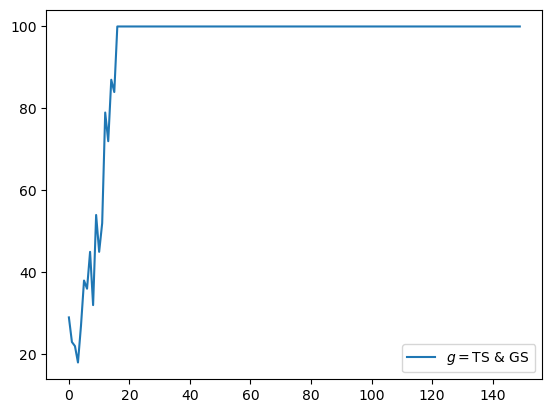

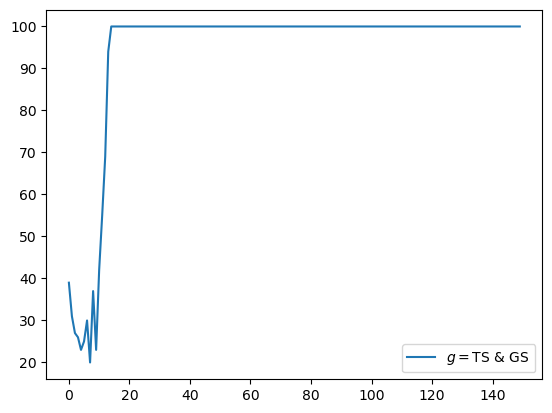

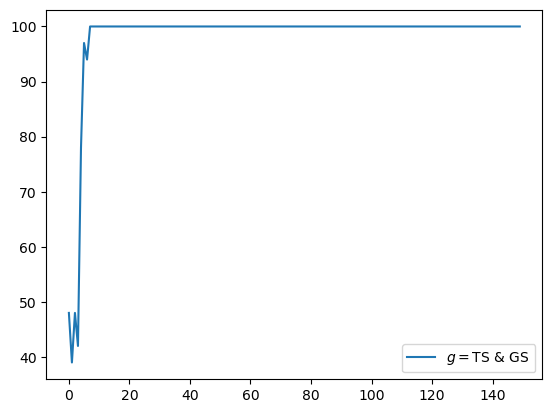

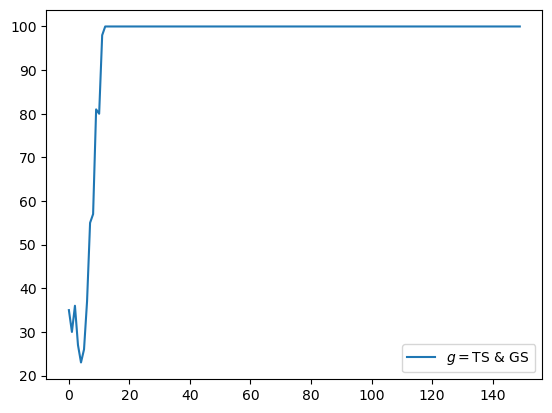

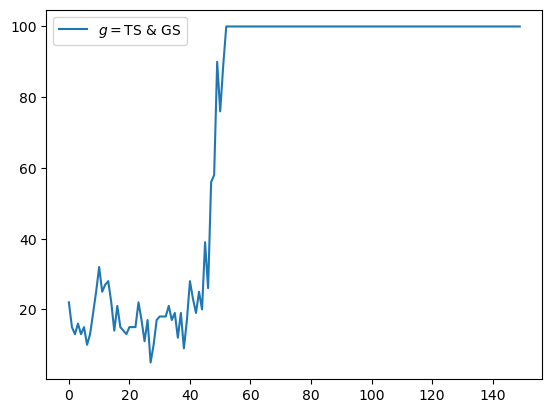

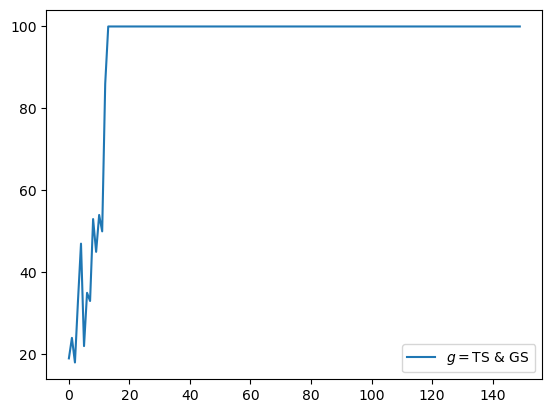

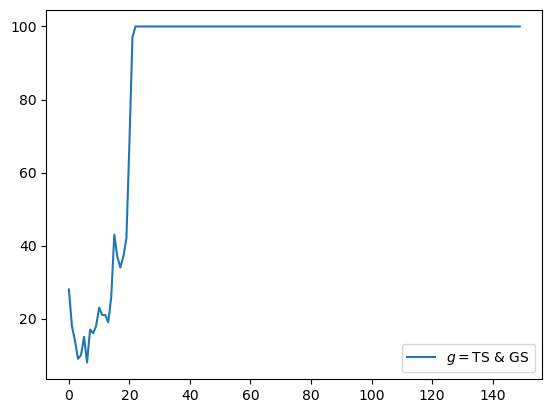

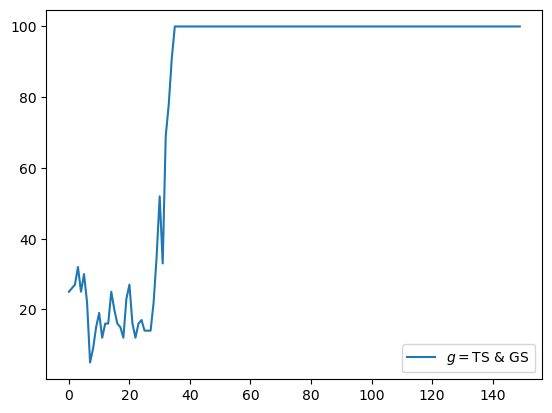

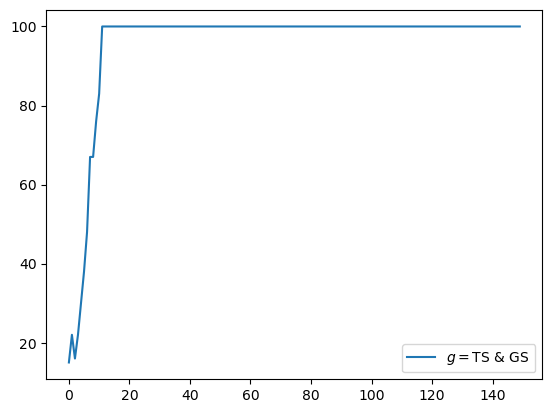

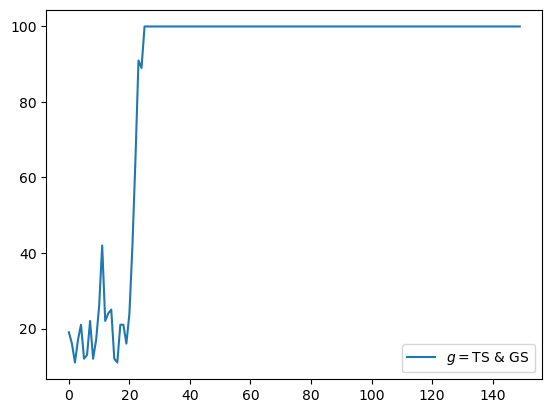

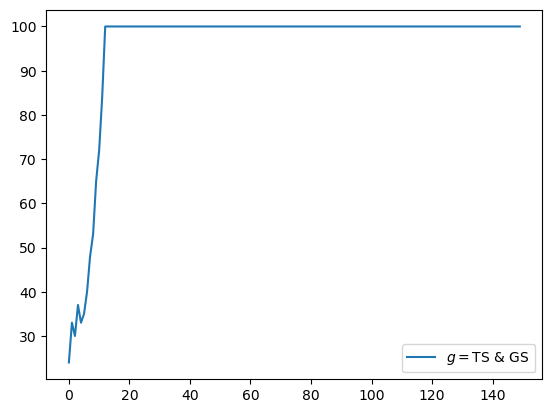

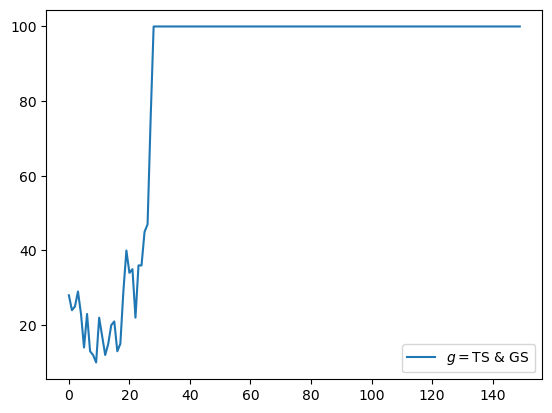

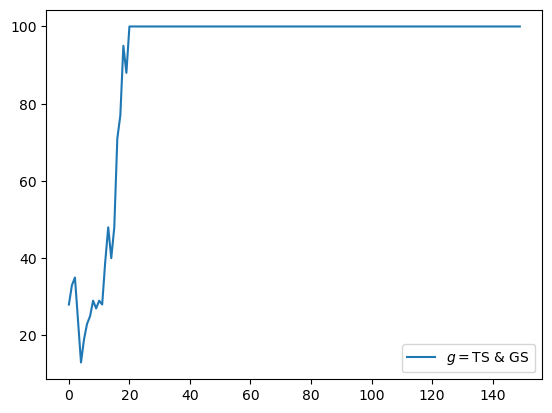

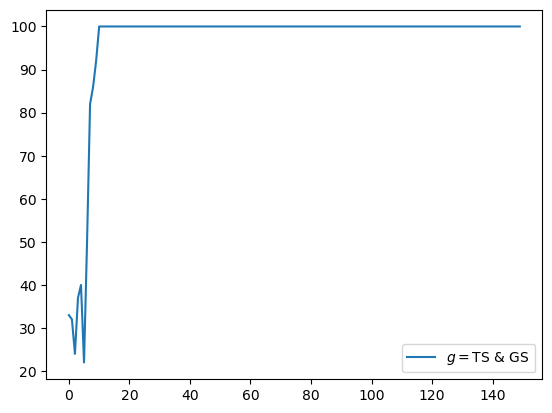

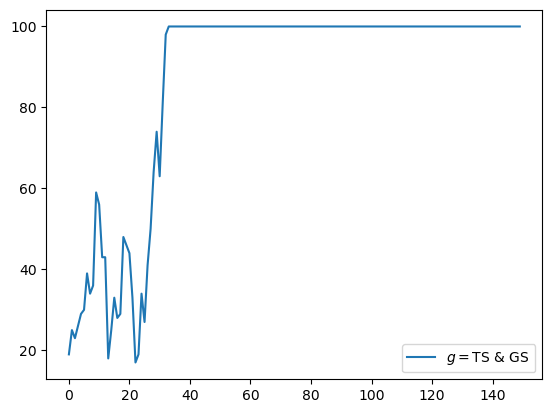

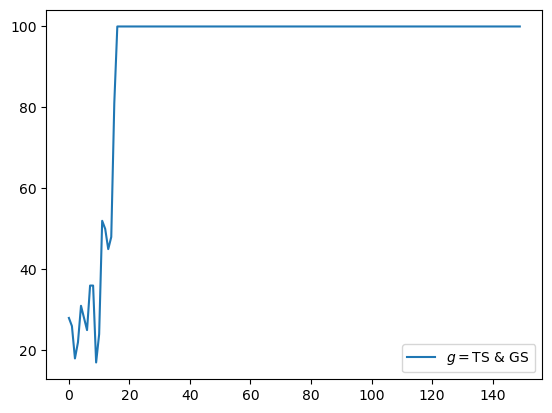

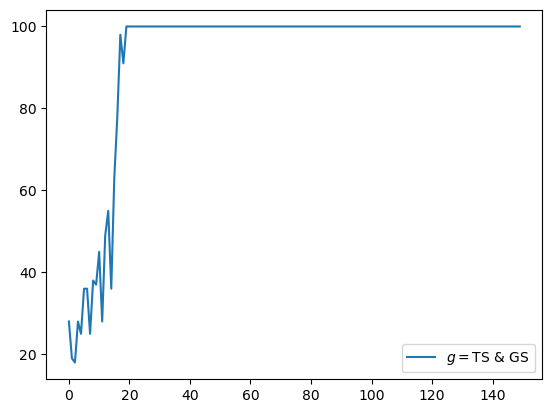

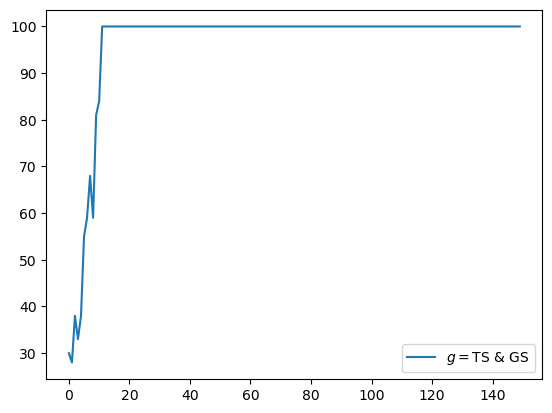

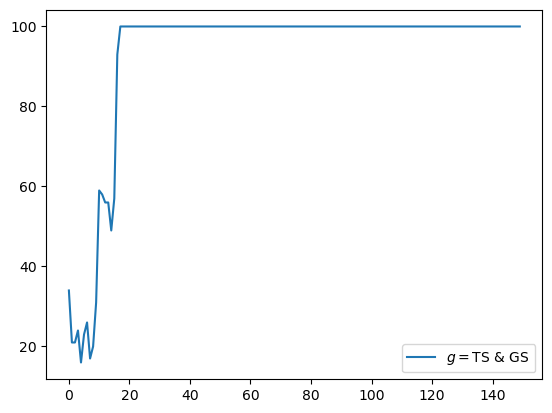

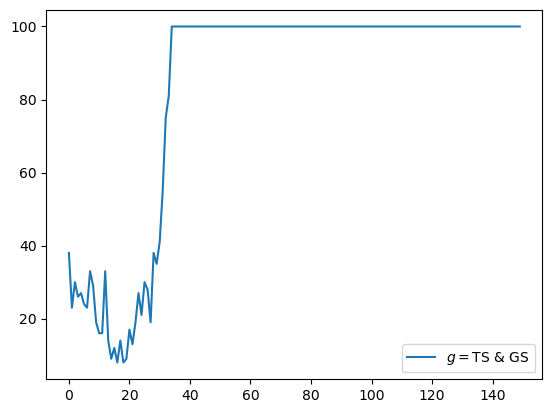

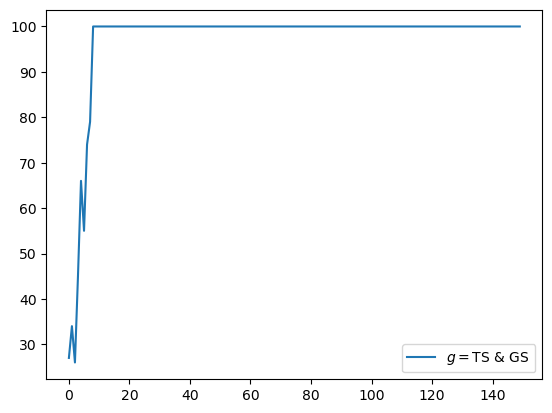

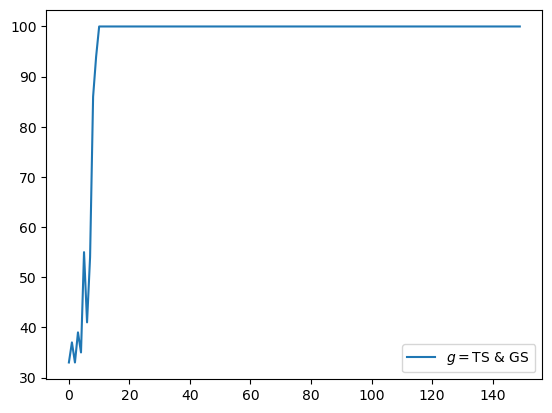

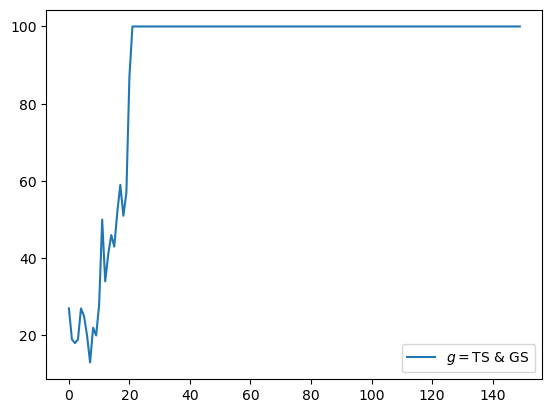

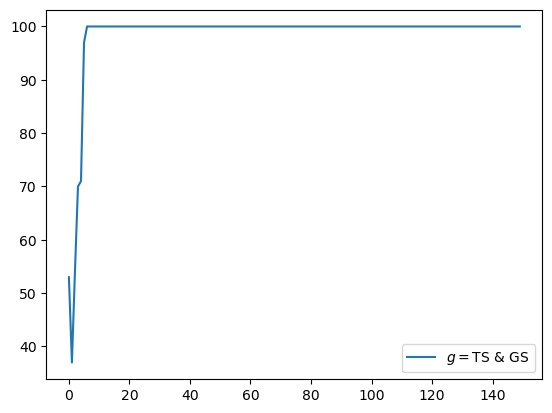

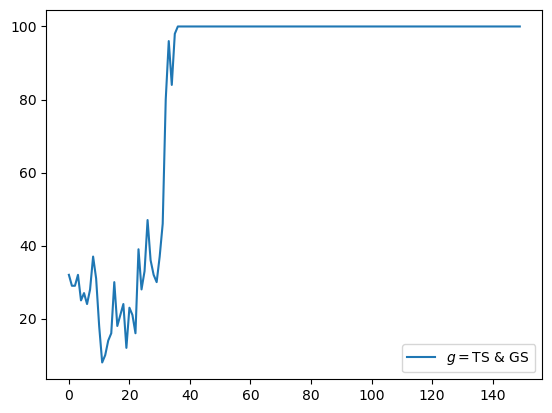

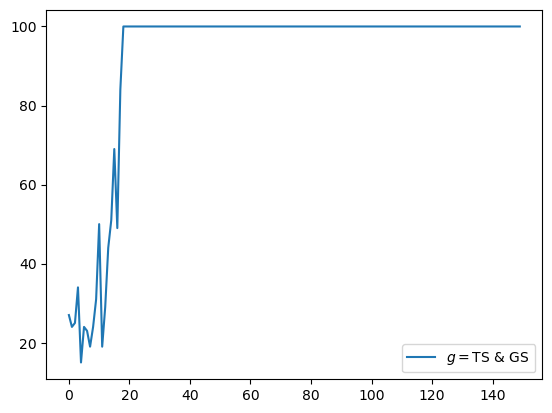

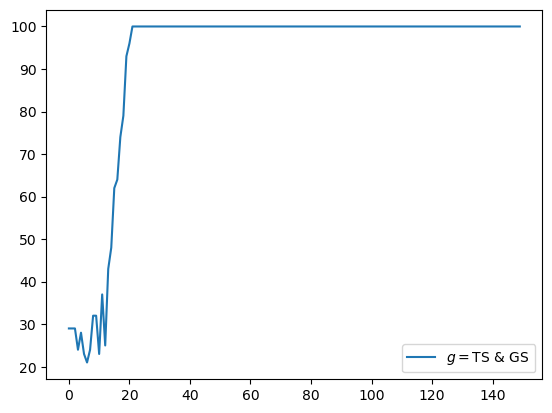

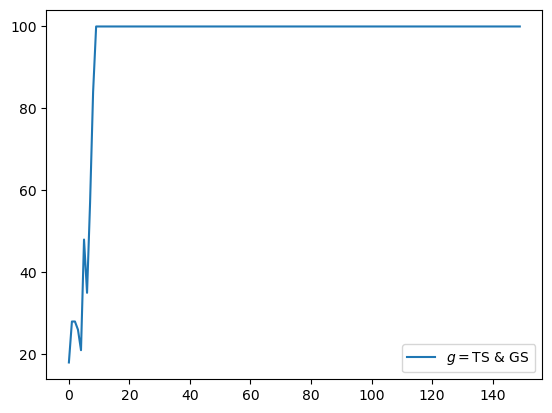

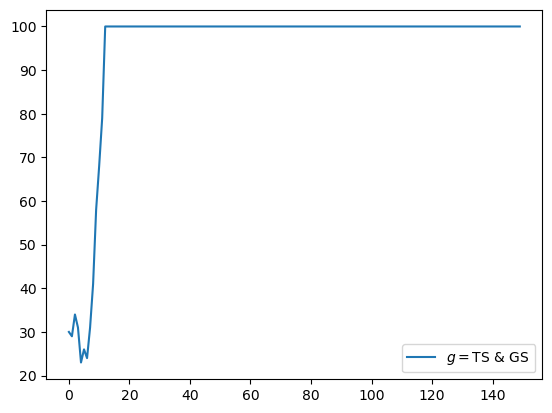

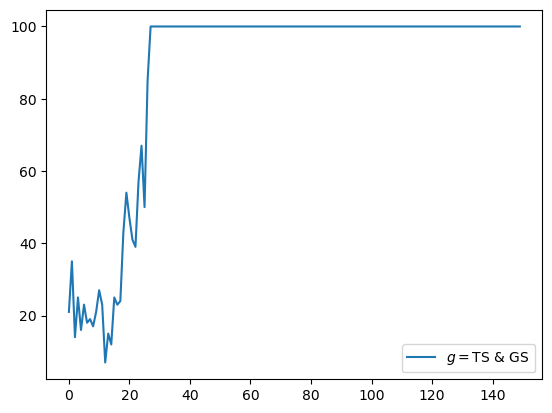

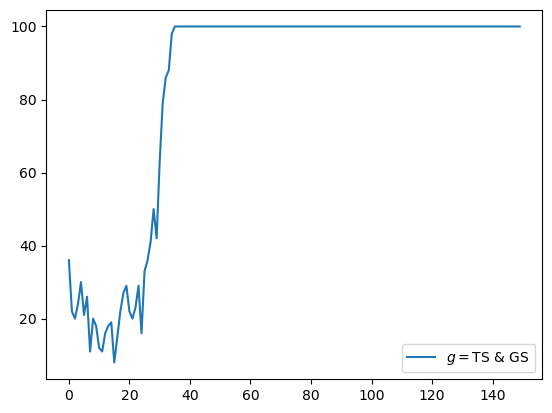

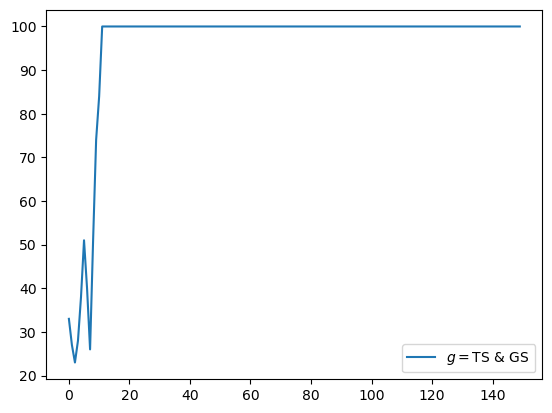

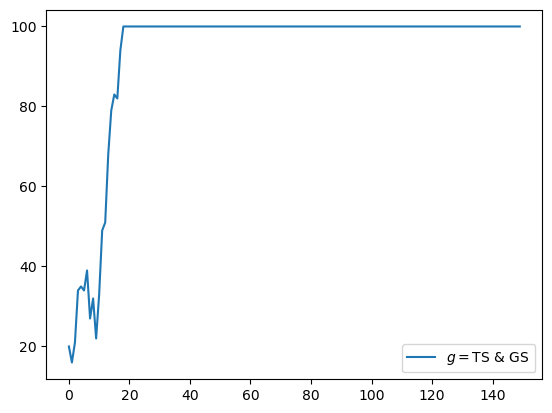

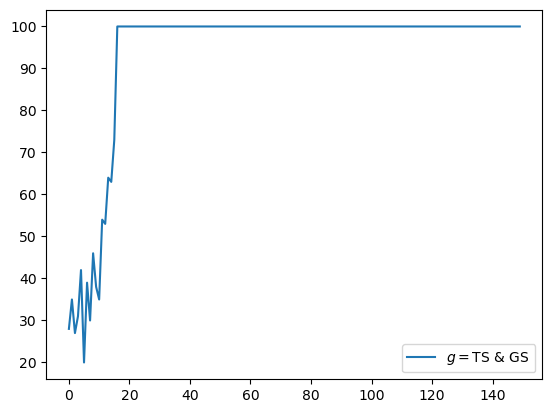

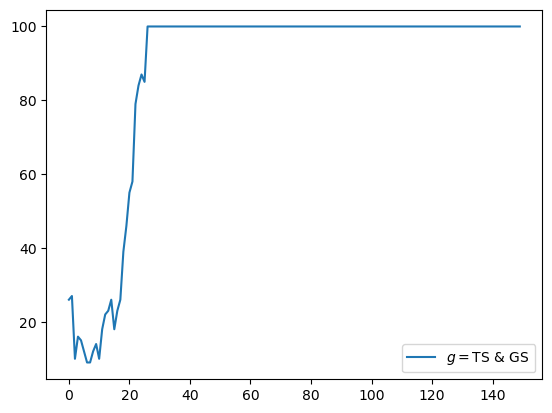

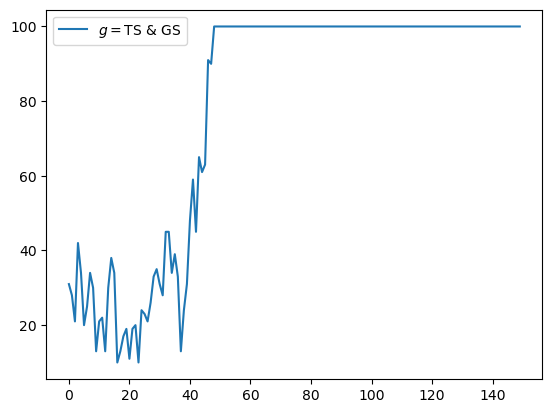

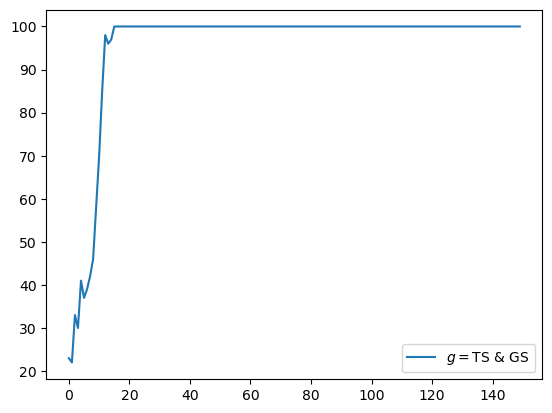

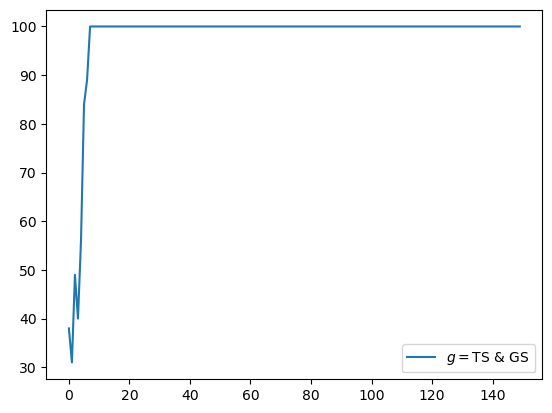

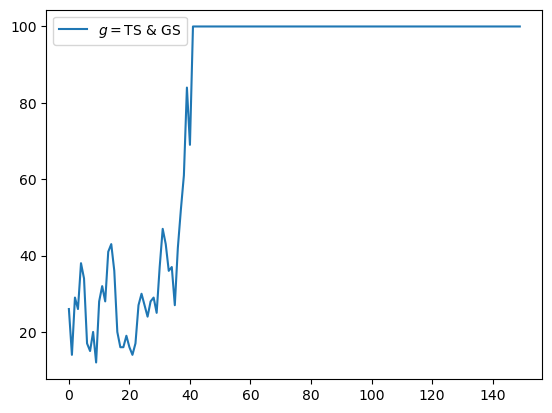

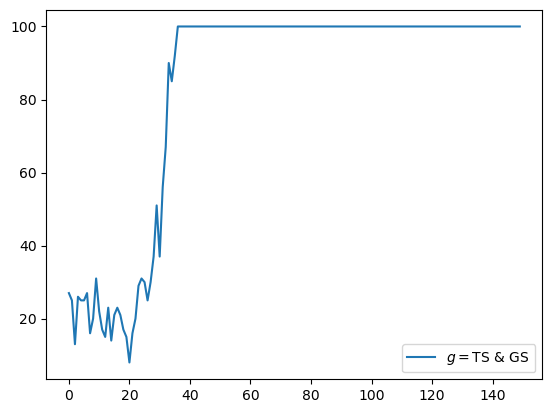

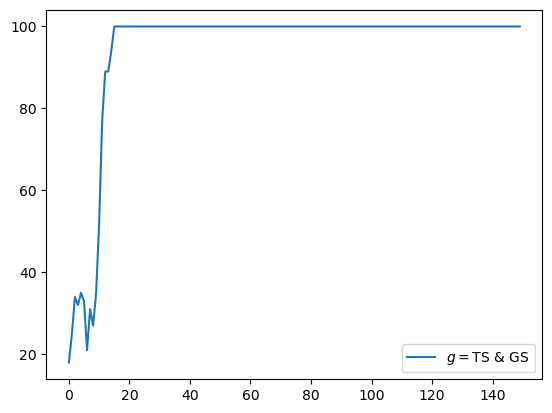

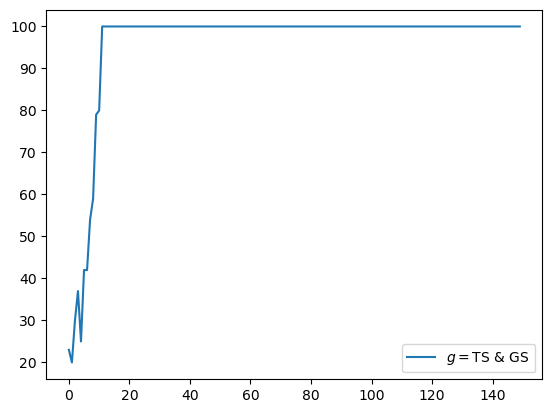

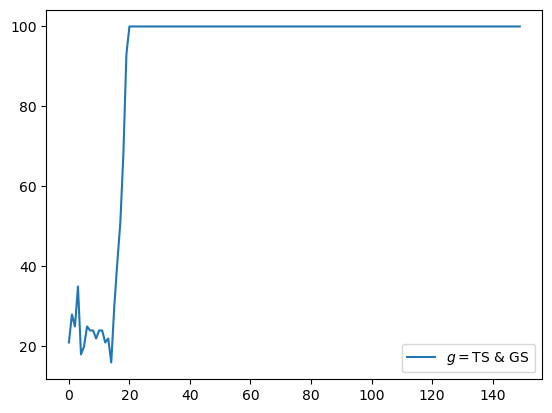

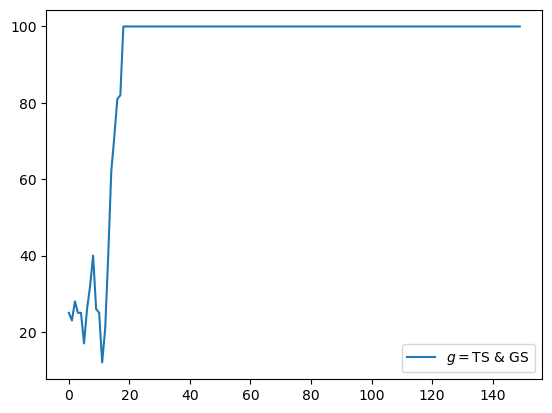

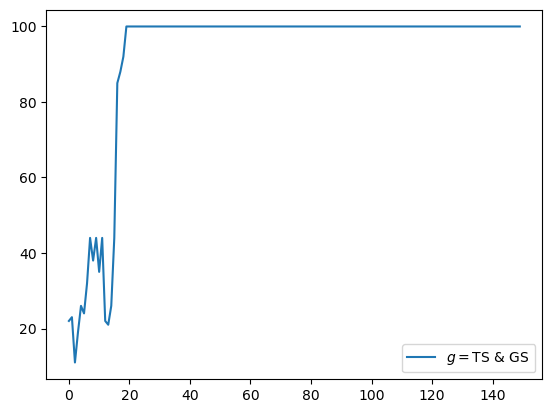

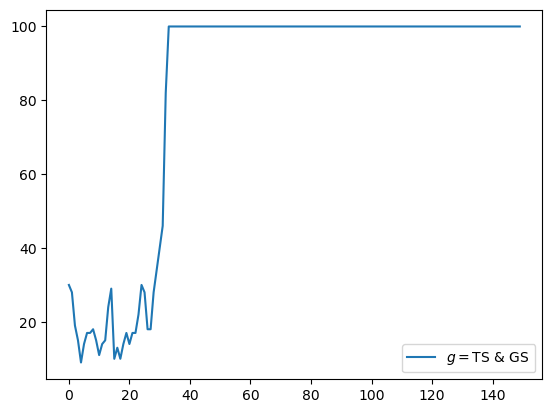

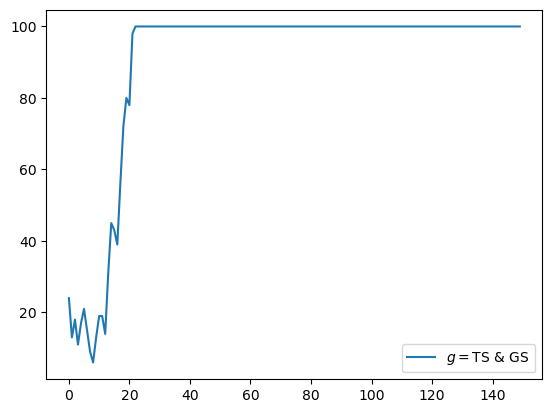

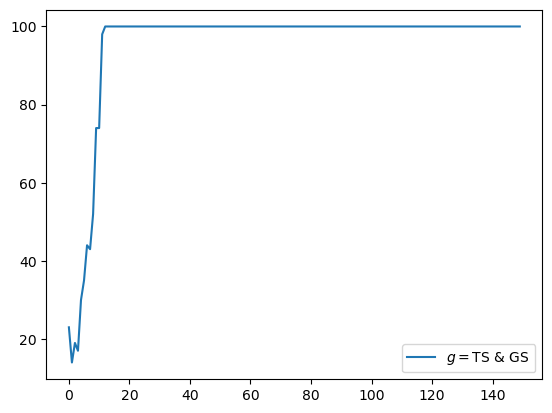

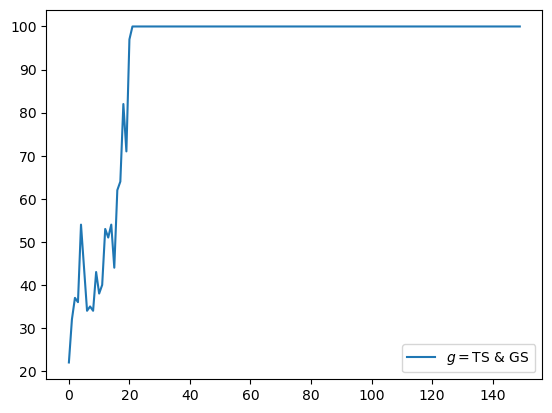

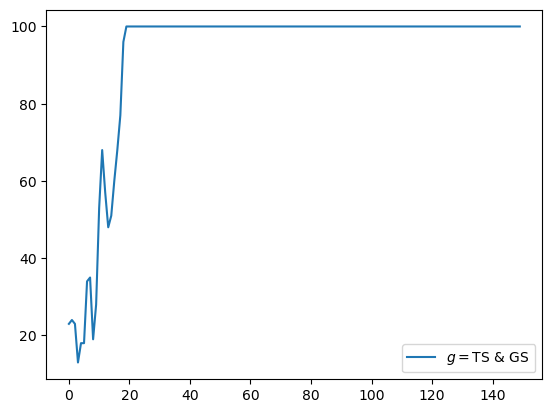

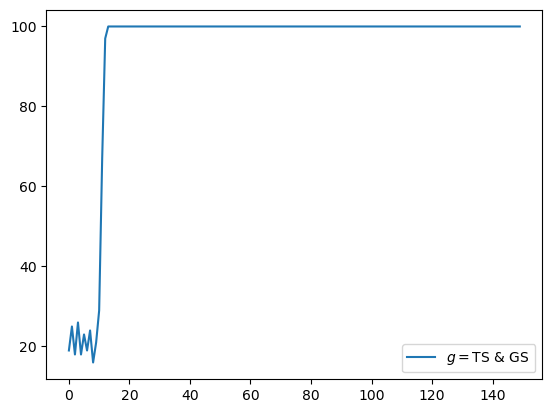

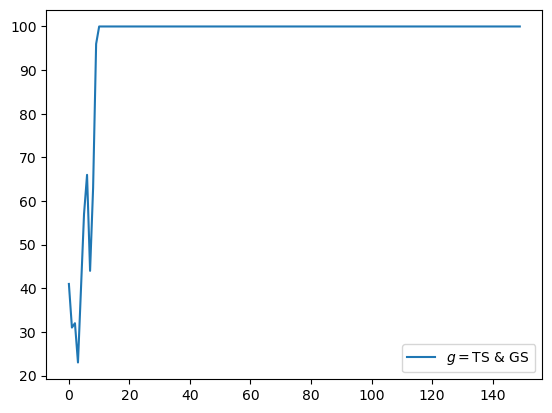

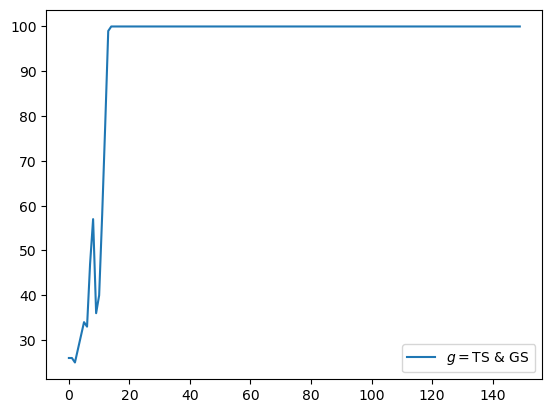

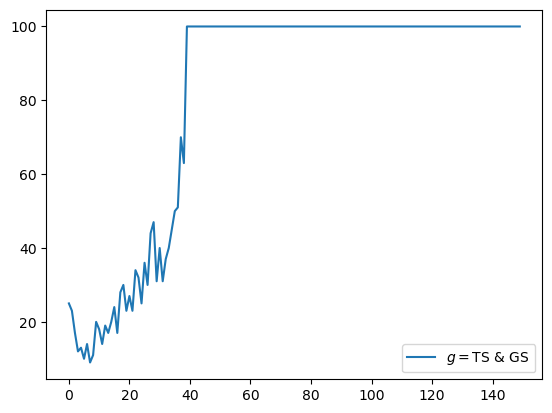

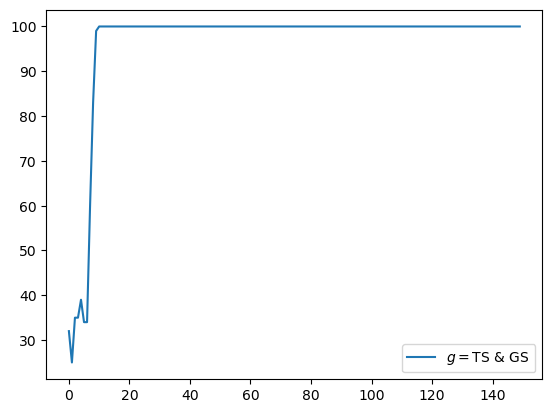

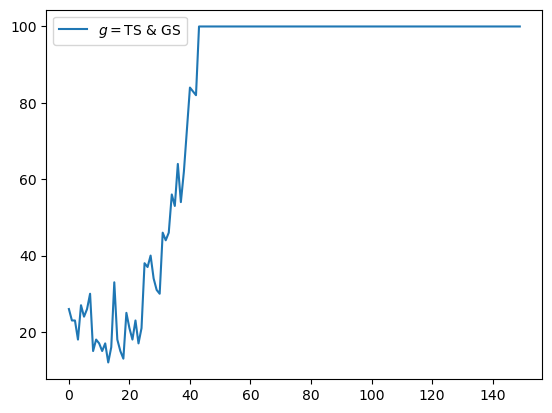

In [20]:
labels = {
    (False, False) : "\\text{TS & GS}",
    (False, True) : "\\text{TS Only}",
    # (True, False) : "\\text{GS Only}",
}

plt.title('GS: equal & probabilistic')
for i in range(len(mechanisms)):
    for j in range(num_simulations):
        try:
            plt.plot(cooperation_per_gen[i][j], label=f'$g={labels[mechanisms[i]]}$')
            plt.legend()
            plt.show()
        except:
            pass
        # plt.fill_between(np.arange(num_generations), mean_cooperation_per_gen[i] - std_cooperation_per_gen[i], 
        #                 mean_cooperation_per_gen[i] + std_cooperation_per_gen[i], alpha=0.2)
# plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5))
# plt.ylabel('Cooperator Count')
# plt.xlabel('Generation')
# plt.grid()
# # plt.savefig("..\\figures\\temp\\mech.png", bbox_inches='tight', transparent=True)
# plt.show()

Dominant Strategy at end of simulation (TS)
	Cooperation: 1
	Defect: 9
	Neither: 0
Dominant Strategy at end of simulation (BOTH)
	Cooperation: 10
	Defect: 0
	Neither: 0
[[4, 2, 3, 3, 3, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5], [4, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

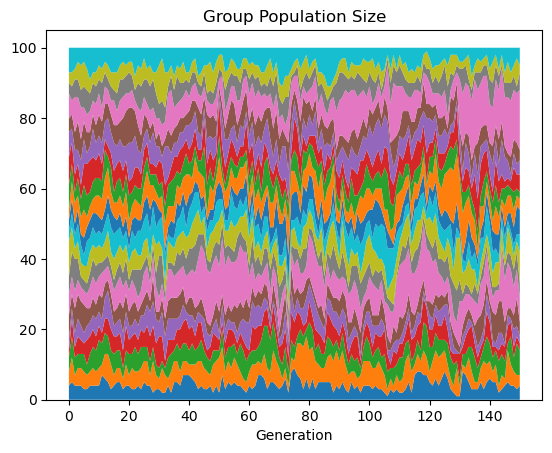

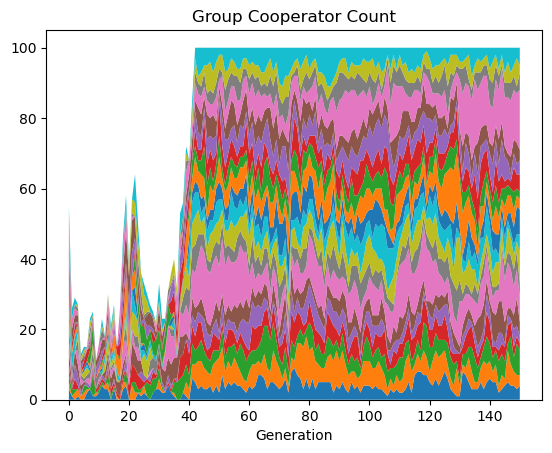

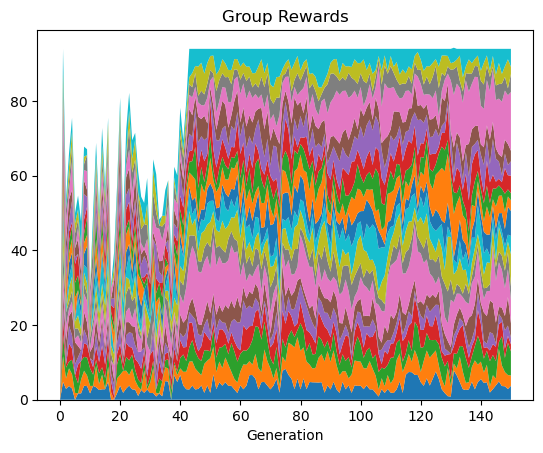

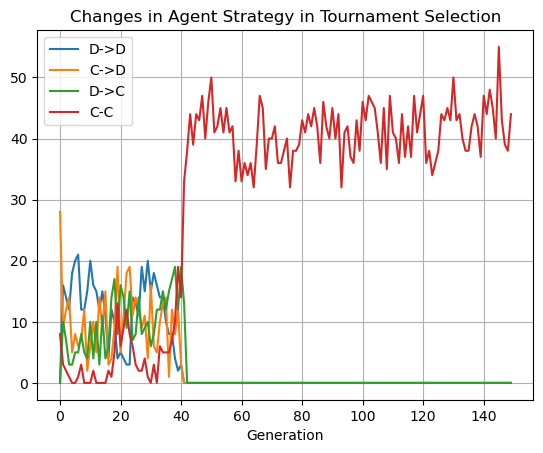

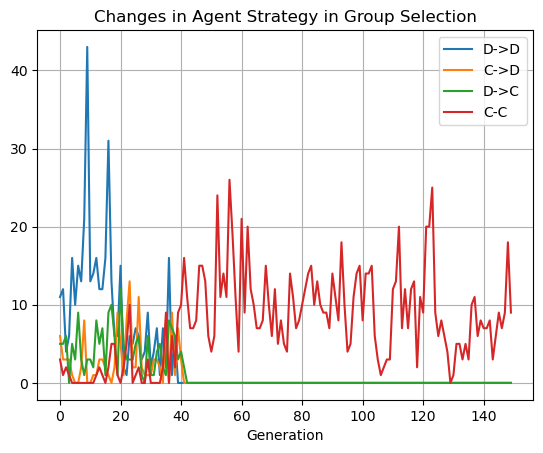

In [7]:

mechanism_idx = 1
sim_idx = 1

ts_coop_dominant = 0
ts_defect_dominant = 0
ts_neither_dominant = 0
for i in range(num_simulations):
    if all_results[0][i][4][-1] == 100:
        ts_coop_dominant += 1
    elif all_results[0][i][4][-1] == 0:
        ts_defect_dominant += 1
    else:
        ts_neither_dominant += 1
print(f'Dominant Strategy at end of simulation (TS)\n\tCooperation: {ts_coop_dominant}\n\tDefect: {ts_defect_dominant}\n\tNeither: {ts_neither_dominant}')


both_coop_dominant = 0
both_defect_dominant = 0
both_neither_dominant = 0
for i in range(num_simulations):
    if all_results[1][i][4][-1] == 100:
        both_coop_dominant += 1
    elif all_results[1][i][4][-1] == 0:
        both_defect_dominant += 1
    else:
        both_neither_dominant += 1
print(f'Dominant Strategy at end of simulation (BOTH)\n\tCooperation: {both_coop_dominant}\n\tDefect: {both_defect_dominant}\n\tNeither: {both_neither_dominant}')



print(all_results[0][sim_idx][0])

# for i in range(num_groups):
#     plt.plot(all_results[0][sim_idx][0][i], label=f'group {i}')

plt.title('Group Population Size')
plt.stackplot(list(range(num_generations + 1)), all_results[mechanism_idx][sim_idx][0])
plt.xlabel('Generation')
plt.show()

plt.title('Group Cooperator Count')
plt.stackplot(list(range(num_generations + 1)), all_results[mechanism_idx][sim_idx][1])
plt.xlabel('Generation')
plt.show()

plt.title('Group Rewards')
plt.stackplot(list(range(num_generations + 1)), all_results[mechanism_idx][sim_idx][2])
plt.xlabel('Generation')
plt.show()

results = all_results[mechanism_idx][sim_idx]
plt.plot(results[6][0])
plt.plot(results[6][1])
plt.plot(results[6][2])
plt.plot(results[6][3])
plt.legend(['D->D', 'C->D', 'D->C', 'C-C'])
plt.title('Changes in Agent Strategy in Tournament Selection')
plt.xlabel('Generation')
plt.grid()
plt.show()

plt.plot(results[7][0])
plt.plot(results[7][1])
plt.plot(results[7][2])
plt.plot(results[7][3])
plt.legend(['D->D', 'C->D', 'D->C', 'C-C'])
plt.title('Changes in Agent Strategy in Group Selection')
plt.xlabel('Generation')
plt.grid()
plt.show()


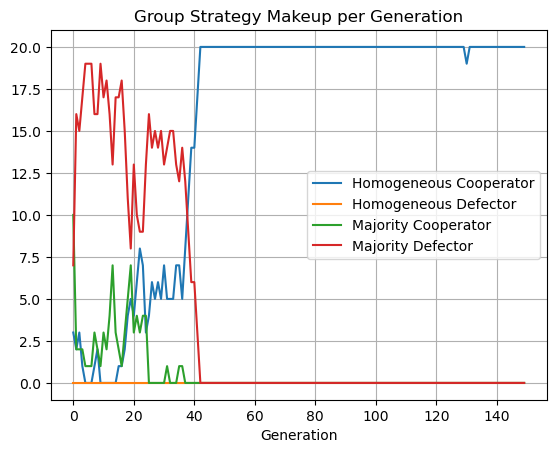

In [8]:

mechanism_idx = 1
sim_idx = 1

group_size = all_results[mechanism_idx][sim_idx][0]
group_coop = all_results[mechanism_idx][sim_idx][1]

homogeneous_cooperator = [0 for _ in range(num_generations)]
homogeneous_defector = [0 for _ in range(num_generations)]
majority_cooperator = [0 for _ in range(num_generations)]
majority_defector = [0 for _ in range(num_generations)]

for sizes, num_coops in zip(group_size, group_coop):
    for gen in range(num_generations):
        if sizes[gen] == 0:
            continue
        elif sizes[gen] == num_coops[gen]:
            homogeneous_cooperator[gen] += 1
        elif sizes[gen] == 0:
            homogeneous_defector[gen] += 1
        elif num_coops[gen] / sizes[gen] >= 0.5:
            majority_cooperator[gen] += 1
        else:
            majority_defector[gen] += 1

plt.plot(homogeneous_cooperator, label='Homogeneous Cooperator')
plt.plot(homogeneous_defector, label='Homogeneous Defector')
plt.plot(majority_cooperator, label='Majority Cooperator')
plt.plot(majority_defector, label='Majority Defector')
plt.legend(loc='best')
plt.title('Group Strategy Makeup per Generation')
plt.xlabel('Generation')
plt.grid()
plt.show()
